# IE 7615 Discriminative Project — Group 2: Final Notebook (Milestones 1, 2 and 3)

One notebook, three parts. Each milestone builds on the one before, and **YOLOv8s (Part 3) is our final model**.

| Part | Milestone | Task | Model(s) | Main result (test set) |
|---|---|---|---|---|
| 1 | Milestone 1 | **Classify** one object per photo (73 Object IDs) | Simple CNN → Deeper CNN → MobileNetV2 → **EfficientNetB0** | EfficientNetB0: **95.1% accuracy**, macro F1 0.951 |
| 2 | Milestone 2 | **Detect and locate** many objects in one image | Box labels with YOLO-World + Grounding DINO, then **YOLOv8s** trained on grid images | (training pipeline; results in Part 3) |
| 3 | Milestone 3 | **Final model**: evaluation, error analysis, live demo | **YOLOv8s** (11.2 M parameters, `imgsz=1120`) | **mAP@0.5 0.912 · mAP@0.5:0.95 0.856 · precision 0.919 · recall 0.883** |

### Why YOLOv8s is the final model
* EfficientNetB0 is very accurate, but it can only give **one ID per image**. It cannot say *where* an object is, or handle many objects.
* YOLOv8s does **both demo tasks** with one model: (a) identify a single-object photo, and (b) identify **and locate** every object in a multi-object image.
* It reuses the Milestone 1 lessons: **transfer learning** from a pretrained model (COCO instead of ImageNet), the same 73 Object IDs, a 70 / 15 / 15 split with seed 42, and a held-out test set used only once.
* Note: accuracy (classification) and mAP (detection) measure different things, so the two numbers are not directly comparable.

### Our group's objects
`FOCUS_IDS = ["OBJ036", "OBJ038"]` (OBJ038 = Dolce & Gabbana Light Blue). These are highlighted in the label checks and results.

### How to run (Google Colab, T4 GPU)
* **Part 1** (TensorFlow, ~60 min) and **Parts 2–3** (PyTorch / Ultralytics, ~2 h) each have their own setup cell, so they can be run separately.
* TensorFlow keeps GPU memory once it has used it. **After Part 1, use *Runtime → Restart session*, then run from Part 2.**
* Trained models are saved to Drive (`milestone1_results/`, `milestone2_final/`), so a re-run of Parts 2–3 skips finished labelling and training and takes ~10–15 min.
* For the **live demo only**, run the single cell in **3.4**. It loads the saved final model and needs nothing else.

> The outputs in this notebook are from our original runs. Part 1 cells are shown in the order they were run
> (MobileNetV2 first), so the comparison table in 1.12 puts the four models side by side.

---
# Part 1 — Milestone 1: Image classification with CNNs

**Goal:** given one photo, predict its Object ID (73 classes). We compare two CNNs trained from scratch with two
transfer-learning models, then pick the best. Built with TensorFlow / Keras.

**Dataset:** the instructor-curated merged dataset, 73 folders (`images_OBJ001` … `images_OBJ073`), 7,343 images,
100–113 per class.

## 1.1 Setup: GPU and Google Drive

In [ ]:
import tensorflow as tf
for g in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(g, True)   # do not reserve the whole GPU
print("GPU:", tf.config.list_physical_devices('GPU'))

from google.colab import drive
drive.mount('/content/drive')

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1.2 Find and copy the dataset

> The dataset folder in our Drive is copied to `/content/data_raw` (local disk is faster than reading from Drive).
> The `cp: cannot create symbolic link` message is harmless: it refers to a shortcut inside the folder; all 73 class folders are copied.

In [ ]:
#Find the dataset from drive

!ls "/content/drive/MyDrive/"
!ls "/content/drive/MyDrive/IE7615 Deep Learning for AI" | head -20

'Colab Notebooks'
'Conference Hall Booking Request Form — RR KABEL LTD..gform'
'Conference Hall Booking — Responses.gsheet'
 HR_Data.pdf
'IE7615 Deep Learning for AI'
'Untitled project.gscript'
images_OBJ001
images_OBJ002
images_OBJ003
images_OBJ004
images_OBJ005
images_OBJ006
images_OBJ007
images_OBJ008
images_OBJ009
images_OBJ010
images_OBJ011
images_OBJ012
images_OBJ013
images_OBJ014
images_OBJ015
images_OBJ016
images_OBJ017
images_OBJ018
images_OBJ019
images_OBJ020


In [ ]:
# Copy the dataset into Colab from drive.

!cp -r "/content/drive/MyDrive/IE7615 Deep Learning for AI" /content/data_raw
!ls /content/data_raw | wc -l


cp: cannot create symbolic link '/content/data_raw/IE7615 Deep Learning for AI': Read-only file system
73


## 1.3 Inspect the dataset

> 73 classes, 100–113 images per class. File types are checked because a few files are `.jpeg` or have no extension.

In [ ]:
# Inspect the dataset

import os
from collections import Counter

SRC = "/content/data_raw"
classes = sorted(d for d in os.listdir(SRC) if d.startswith("images_OBJ"))
print(len(classes), "classes")

counts, exts = {}, Counter()
for c in classes:
    files = os.listdir(os.path.join(SRC, c))
    counts[c] = len(files)
    exts.update(os.path.splitext(f)[1].lower() for f in files)

print("Images per class: min", min(counts.values()), "max", max(counts.values()))
print("File types:", exts)
for c, n in counts.items():
    if n < 90:
        print("Low count:", c, n)

73 classes
Images per class: min 100 max 113
File types: Counter({'.jpg': 7136, '.jpeg': 207, '': 2})


## 1.4 Split into train / validation / test (70 / 15 / 15)

> The split is made **per class** (so every class has the same 70 / 15 / 15 ratio) with `random.seed(42)`.
> Result: 5,138 train, 1,098 val and 1,107 test images. The test set is used only for the final evaluation.

In [ ]:
# Split into train, validation, and test

import random, shutil

random.seed(42)
DST = "/content/data_split"
IMG_EXTS = (".jpg", ".jpeg", ".png")

for c in classes:
    files = sorted(f for f in os.listdir(os.path.join(SRC, c)) if f.lower().endswith(IMG_EXTS))
    random.shuffle(files)
    n = len(files)
    n_train, n_val = int(0.70 * n), int(0.15 * n)
    splits = {"train": files[:n_train],
              "val":   files[n_train:n_train + n_val],
              "test":  files[n_train + n_val:]}
    label = c.replace("images_", "")          # folder becomes e.g. OBJ038
    for split, file_list in splits.items():
        os.makedirs(os.path.join(DST, split, label), exist_ok=True)
        for f in file_list:
            shutil.copy(os.path.join(SRC, c, f), os.path.join(DST, split, label, f))

for split in ["train", "val", "test"]:
    total = sum(len(os.listdir(os.path.join(DST, split, l))) for l in os.listdir(os.path.join(DST, split)))
    print(split, total, "images")

train 5138 images
val 1098 images
test 1107 images


## 1.5 Load the datasets

> Images are resized to 224 × 224 and loaded in batches of 32. Labels are integers (one per Object ID).

In [ ]:
#Load the datasets

IMG_SIZE = (224, 224)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        f"{DST}/{split}", image_size=IMG_SIZE, batch_size=BATCH,
        label_mode="int", shuffle=shuffle, seed=42)

train_ds = load("train", True)
val_ds   = load("val", False)
test_ds  = load("test", False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print(NUM_CLASSES, "classes:", class_names[:5], "...")

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 5138 files belonging to 73 classes.
Found 1098 files belonging to 73 classes.
Found 1107 files belonging to 73 classes.
73 classes: ['OBJ001', 'OBJ002', 'OBJ003', 'OBJ004', 'OBJ005'] ...


## 1.6 Data augmentation

> Random flips, rotations, zoom, contrast and brightness, applied only during training.
> This helps the models generalise because each class has only ~70 training photos.

In [ ]:
#Data augmentation

from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
], name="augmentation")

## 1.7 Shared evaluation and plotting helpers

> Every model is evaluated the same way on the test set: accuracy, macro precision, recall and F1, number of
> parameters and training time. Predictions are saved to `milestone1_results/` in Drive.

In [ ]:
#Shared evaluation and plotting helpers

import time, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = {}
SAVE_DIR = "/content/drive/MyDrive/milestone1_results"
os.makedirs(SAVE_DIR, exist_ok=True)

def evaluate_model(model, name, train_time):
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    results[name] = {
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall":    recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1":        f1_score(y_true, y_pred, average="macro", zero_division=0),
        "params_M":  model.count_params() / 1e6,
        "train_min": train_time / 60,
    }
    np.save(f"{SAVE_DIR}/{name}_preds.npy", np.stack([y_true, y_pred]))
    print(name, {k: round(v, 4) for k, v in results[name].items()})

def plot_history(h, name):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, m in enumerate(["accuracy", "loss"]):
        ax[i].plot(h.history[m], label="train")
        ax[i].plot(h.history[f"val_{m}"], label="val")
        ax[i].set_title(f"{name} {m}")
        ax[i].set_xlabel("epoch")
        ax[i].legend()
    plt.show()

## 1.8 Model A: MobileNetV2 (transfer learning)

> MobileNetV2 pretrained on ImageNet, base frozen, new classifier head (dropout 0.3 + softmax).
> Adam 1e-3, up to 20 epochs, early stopping (patience 5).

In [ ]:
#Train MobileNetV2 (transfer learning)

base = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs  = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
mobilenet = tf.keras.Model(inputs, outputs, name="MobileNetV2")

mobilenet.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=5, restore_best_weights=True)

start = time.time()
hist_mobilenet = mobilenet.fit(train_ds, validation_data=val_ds,
                               epochs=20, callbacks=[early])
time_mobilenet = time.time() - start

Epoch 1/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 18s 83ms/step - accuracy: 0.4307 - loss: 2.5913 - val_accuracy: 0.7450 - val_loss: 1.2079
Epoch 2/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - accuracy: 0.7567 - loss: 1.0453 - val_accuracy: 0.8106 - val_loss: 0.8489
Epoch 3/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 13s 78ms/step - accuracy: 0.8328 - loss: 0.7246 - val_accuracy: 0.8406 - val_loss: 0.6955
Epoch 4/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - accuracy: 0.8638 - loss: 0.5830 - val_accuracy: 0.8497 - val_loss: 0.6383
Epoch 5/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.8809 - loss: 0.4880 - val_accuracy: 0.8607 - val_loss: 0.5857
Epoch 6/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - accuracy: 0.9029 - loss: 0.4101 - val_accuracy: 0.8643 - val_loss: 0.5450
Epoch 7/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 12s 74ms/step - accuracy: 0.9099 - loss: 0.3549 - val_accuracy: 0.8707 - val_loss: 0.5319
Epoch 8/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 12s 74ms/step - accuracy: 0.9229 - loss: 0.3099 - 

> **Evaluate and save** MobileNetV2: test metrics, training curves, model saved to Drive.

MobileNetV2 {'accuracy': 0.9061, 'precision': 0.9166, 'recall': 0.9066, 'f1': 0.9068, 'params_M': 2.3515, 'train_min': 4.3289}


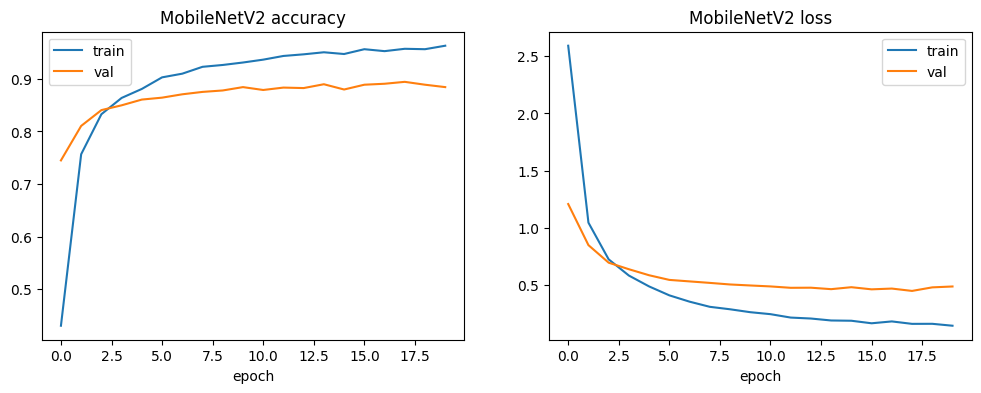

In [ ]:
#Evaluate and save
evaluate_model(mobilenet, "MobileNetV2", time_mobilenet)
plot_history(hist_mobilenet, "MobileNetV2")
mobilenet.save(f"{SAVE_DIR}/MobileNetV2.keras")

## 1.9 Model B: Simple CNN (from scratch)

> Baseline: 3 convolution blocks (32 / 64 / 128 filters), global average pooling, dense 128, dropout 0.3.
> Adam 1e-3, up to 40 epochs, early stopping (patience 7).

In [ ]:
#Build and train the custom CNN
cnn = tf.keras.Sequential([
    tf.keras.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="SimpleCNN")

cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_cnn = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=7, restore_best_weights=True)

start = time.time()
hist_cnn = cnn.fit(train_ds, validation_data=val_ds,
                   epochs=40, callbacks=[early_cnn])
time_cnn = time.time() - start

Epoch 1/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accuracy: 0.0169 - loss: 4.2865 - val_accuracy: 0.0155 - val_loss: 4.2406
Epoch 2/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.0315 - loss: 4.1655 - val_accuracy: 0.0474 - val_loss: 4.0944
Epoch 3/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.0487 - loss: 4.0399 - val_accuracy: 0.0556 - val_loss: 3.9480
Epoch 4/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - accuracy: 0.0553 - loss: 3.9518 - val_accuracy: 0.0756 - val_loss: 3.8135
Epoch 5/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.0724 - loss: 3.8495 - val_accuracy: 0.0883 - val_loss: 3.7931
Epoch 6/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 9s 57ms/step - accuracy: 0.0903 - loss: 3.7493 - val_accuracy: 0.1129 - val_loss: 3.6040
Epoch 7/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.1119 - loss: 3.6292 - val_accuracy: 0.1512 - val_loss: 3.4997
Epoch 8/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.1294 - loss: 3.5231 - v

> **Evaluate and save** the Simple CNN.

SimpleCNN {'accuracy': 0.4959, 'precision': 0.5175, 'recall': 0.4965, 'f1': 0.4705, 'params_M': 0.1192, 'train_min': 6.4001}


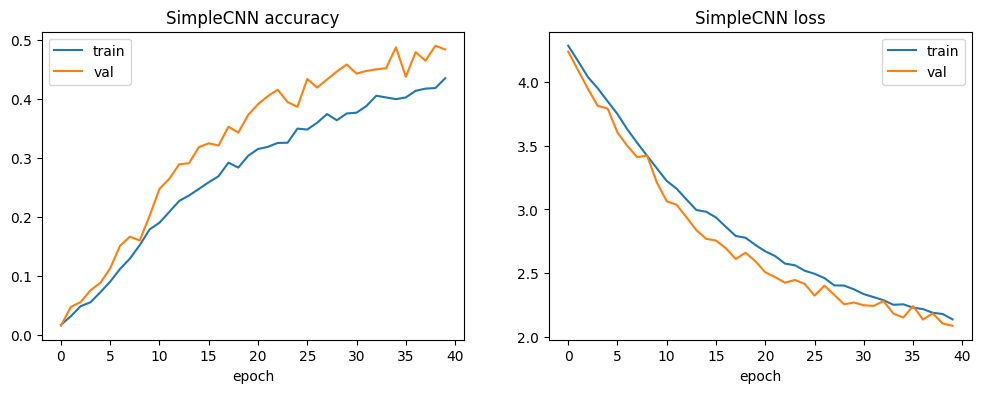

In [ ]:
#Evaluate and save

evaluate_model(cnn, "SimpleCNN", time_cnn)
plot_history(hist_cnn, "SimpleCNN")
cnn.save(f"{SAVE_DIR}/SimpleCNN.keras")

## 1.10 Model C: EfficientNetB0 with two-phase fine-tuning

> EfficientNetB0 pretrained on ImageNet.
> * **Phase 1:** base frozen, train only the new head (Adam 1e-3, up to 15 epochs).
> * **Phase 2:** unfreeze the top 40 layers (batch-norm layers stay frozen) and fine-tune with a low learning rate (Adam 1e-5, up to 15 epochs).
>
> Early stopping (patience 5) in both phases. The two training histories are joined for the plot.

In [ ]:
#Build and train EfficientNetB0

base_eff = tf.keras.applications.EfficientNetB0(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base_eff.trainable = False

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = base_eff(x, training=False)          # EfficientNet handles its own preprocessing
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
effnet = tf.keras.Model(inputs, outputs, name="EfficientNetB0")

# Phase 1: train the head only
effnet.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
start = time.time()
hist_eff1 = effnet.fit(train_ds, validation_data=val_ds, epochs=15,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=5, restore_best_weights=True)])

# Phase 2: fine-tune the top 40 layers
base_eff.trainable = True
for layer in base_eff.layers[:-40]:
    layer.trainable = False
for layer in base_eff.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

effnet.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_eff2 = effnet.fit(train_ds, validation_data=val_ds, epochs=15,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=5, restore_best_weights=True)])
time_eff = time.time() - start

Epoch 1/15
161/161 ━━━━━━━━━━━━━━━━━━━━ 29s 122ms/step - accuracy: 0.4982 - loss: 2.6118 - val_accuracy: 0.7996 - val_loss: 1.2654
Epoch 2/15
161/161 ━━━━━━━━━━━━━━━━━━━━ 16s 98ms/step - accuracy: 0.8085 - loss: 1.0963 - val_accuracy: 0.8525 - val_loss: 0.7871
Epoch 3/15
161/161 ━━━━━━━━━━━━━━━━━━━━ 16s 97ms/step - accuracy: 0.8626 - loss: 0.7450 - val_accuracy: 0.8752 - val_loss: 0.6140
Epoch 4/15
161/161 ━━━━━━━━━━━━━━━━━━━━ 16s 96ms/step - accuracy: 0.8945 - loss: 0.5656 - val_accuracy: 0.8934 - val_loss: 0.5196
Epoch 5/15
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 96ms/step - accuracy: 0.9165 - loss: 0.4587 - val_accuracy: 0.9026 - val_loss: 0.4597
Epoch 6/15
161/161 ━━━━━━━━━━━━━━━━━━━━ 16s 97ms/step - accuracy: 0.9301 - loss: 0.3826 - val_accuracy: 0.9135 - val_loss: 0.4165
Epoch 7/15
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 97ms/step - accuracy: 0.9377 - loss: 0.3227 - val_accuracy: 0.9144 - val_loss: 0.3965
Epoch 8/15
161/161 ━━━━━━━━━━━━━━━━━━━━ 16s 98ms/step - accuracy: 0.9482 - loss: 0.2936 -

> **Evaluate and save** EfficientNetB0 (both training phases in one plot).

EfficientNetB0_FT {'accuracy': 0.9512, 'precision': 0.9542, 'recall': 0.9512, 'f1': 0.9513, 'params_M': 4.1431, 'train_min': 9.2315}


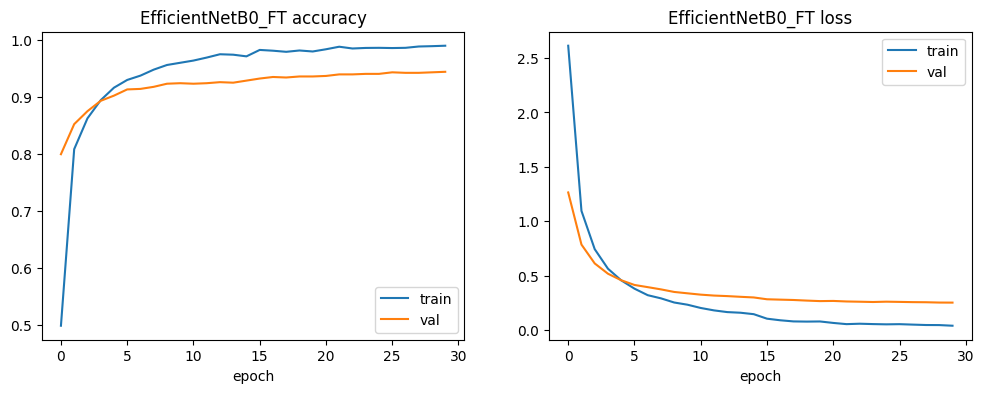

In [ ]:
#Evaluate and save

class CombinedHistory:
    def __init__(self, h1, h2):
        self.history = {k: h1.history[k] + h2.history[k] for k in h1.history}

hist_eff = CombinedHistory(hist_eff1, hist_eff2)
evaluate_model(effnet, "EfficientNetB0_FT", time_eff)
plot_history(hist_eff, "EfficientNetB0_FT")
effnet.save(f"{SAVE_DIR}/EfficientNetB0_FT.keras")

> Quick check of which results are in memory. The Deeper CNN (1.11) was trained after this cell.

In [ ]:
print(results.keys())

dict_keys(['MobileNetV2', 'SimpleCNN', 'EfficientNetB0_FT'])


## 1.11 Model D: Deeper CNN (from scratch)

> 4 double-convolution blocks (32 → 256 filters) with **batch normalization**, dense 256, dropout 0.5.
> Learning-rate schedule: `ReduceLROnPlateau` halves the rate when validation loss stops improving.
> Up to 40 epochs, early stopping (patience 8).

In [ ]:
#Build and train the deeper CNN

def conv_block(filters):
    return [
        layers.Conv2D(filters, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(filters, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),
    ]

deep_cnn = tf.keras.Sequential([
    tf.keras.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,
    layers.Rescaling(1./255),
    *conv_block(32), *conv_block(64), *conv_block(128), *conv_block(256),
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="DeepCNN")

deep_cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks_deep = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8,
                                     restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=3, verbose=1),
]

start = time.time()
hist_deep = deep_cnn.fit(train_ds, validation_data=val_ds,
                         epochs=40, callbacks=callbacks_deep)
time_deep = time.time() - start

Epoch 1/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 54s 310ms/step - accuracy: 0.0224 - loss: 4.2532 - val_accuracy: 0.0182 - val_loss: 4.2769 - learning_rate: 0.0010
Epoch 2/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 49s 302ms/step - accuracy: 0.0440 - loss: 4.0705 - val_accuracy: 0.0091 - val_loss: 4.8596 - learning_rate: 0.0010
Epoch 3/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 49s 305ms/step - accuracy: 0.0588 - loss: 3.9169 - val_accuracy: 0.0501 - val_loss: 3.9174 - learning_rate: 0.0010
Epoch 4/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 49s 303ms/step - accuracy: 0.0961 - loss: 3.7367 - val_accuracy: 0.0601 - val_loss: 4.0536 - learning_rate: 0.0010
Epoch 5/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 49s 304ms/step - accuracy: 0.1179 - loss: 3.5984 - val_accuracy: 0.1430 - val_loss: 3.5380 - learning_rate: 0.0010
Epoch 6/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 49s 304ms/step - accuracy: 0.1357 - loss: 3.4978 - val_accuracy: 0.0856 - val_loss: 4.5535 - learning_rate: 0.0010
Epoch 7/40
161/161 ━━━━━━━━━━━━━━━━━━━━ 49s 303ms/step - accuracy: 0.1

> **Evaluate and save** the Deeper CNN.

DeepCNN {'accuracy': 0.5519, 'precision': 0.5551, 'recall': 0.5522, 'f1': 0.5302, 'params_M': 1.2597, 'train_min': 33.8581}


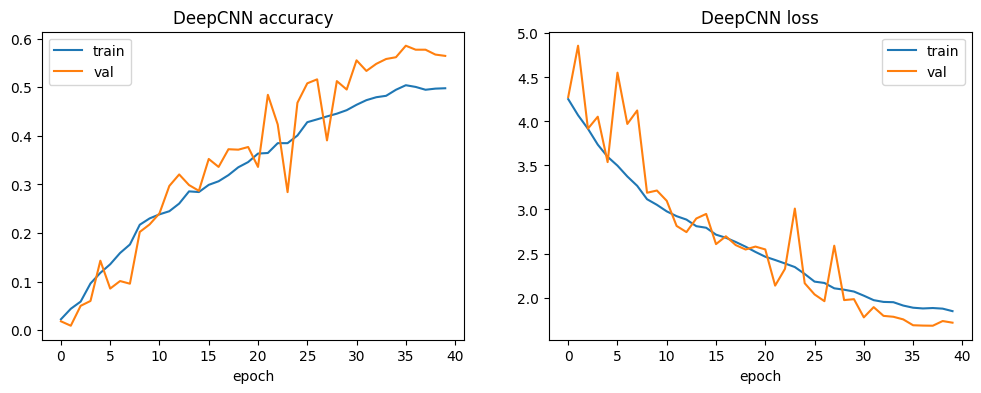

In [ ]:
#Evaluate and save

evaluate_model(deep_cnn, "DeepCNN", time_deep)
plot_history(hist_deep, "DeepCNN")
deep_cnn.save(f"{SAVE_DIR}/DeepCNN.keras")

## 1.12 Model comparison

> All four models on the same test set (1,107 images).

In [ ]:
#Final comparison table

import pandas as pd

known = {  # (params_M, train_min) from earlier outputs, used only if missing in memory
    "SimpleCNN": (0.1192, 6.52),
    "MobileNetV2": (2.3515, 4.46),
    "EfficientNetB0_FT": (4.1431, 9.27),
}

rows = []
for name in ["SimpleCNN", "DeepCNN", "MobileNetV2", "EfficientNetB0_FT"]:
    y_true, y_pred = np.load(f"{SAVE_DIR}/{name}_preds.npy")
    if name in results:
        params, mins = results[name]["params_M"], results[name]["train_min"]
    else:
        params, mins = known.get(name, (np.nan, np.nan))
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1":        f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Params (M)": params,
        "Train time (min)": mins,
    })

comparison = pd.DataFrame(rows).set_index("Model").round(4)
comparison.to_csv(f"{SAVE_DIR}/model_comparison.csv")
display(comparison)

,Accuracy,Precision,Recall,F1,Params (M),Train time (min)
Model,,,,,,
SimpleCNN,0.4959,0.5175,0.4965,0.4705,0.1192,6.4001
DeepCNN,0.5519,0.5551,0.5522,0.5302,1.2597,33.8581
MobileNetV2,0.9061,0.9166,0.9066,0.9068,2.3515,4.3289
EfficientNetB0_FT,0.9512,0.9542,0.9512,0.9513,4.1431,9.2315


## 1.13 Confusion matrix and error analysis (EfficientNetB0)

> Shows the most confused Object ID pairs and the classes with the lowest F1 score.

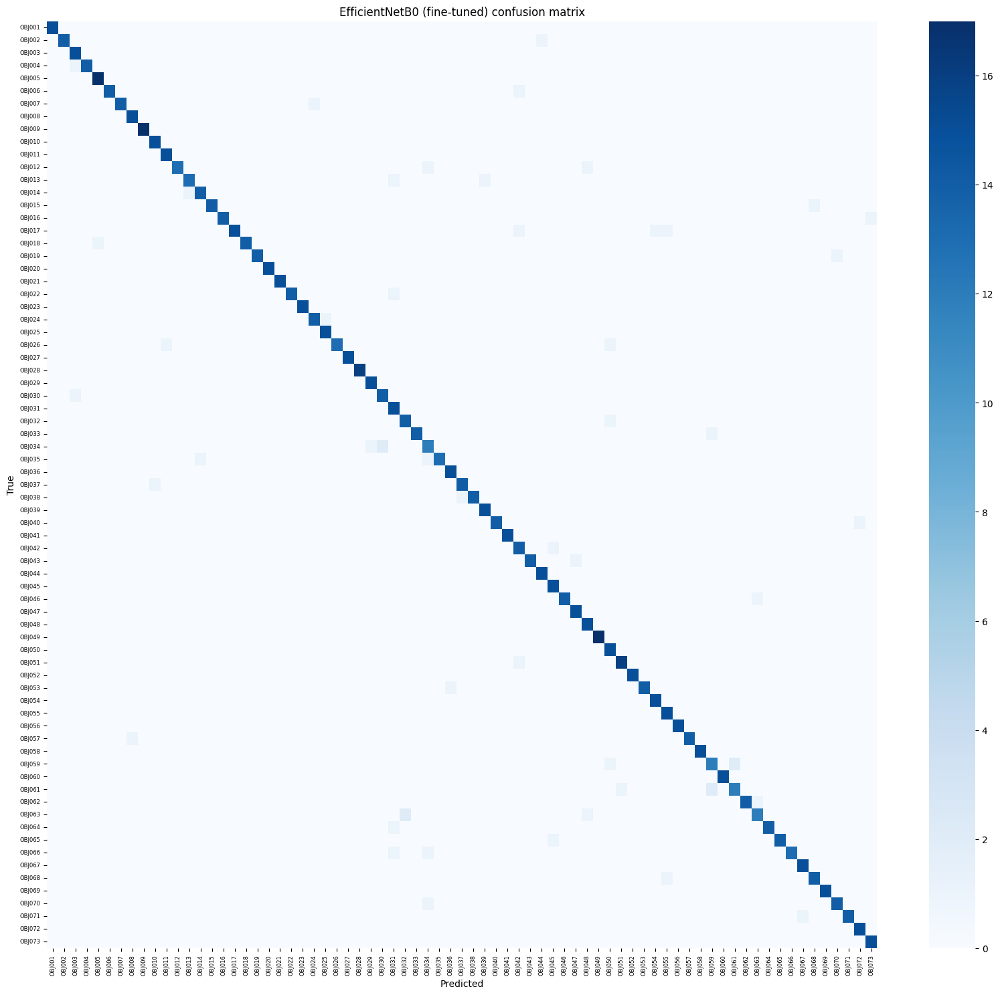

Most confused pairs (true -> predicted: count)
  OBJ059 -> OBJ061: 2
  OBJ034 -> OBJ030: 2
  OBJ063 -> OBJ032: 2
  OBJ061 -> OBJ059: 2
  OBJ038 -> OBJ037: 1
  OBJ042 -> OBJ045: 1
  OBJ035 -> OBJ014: 1
  OBJ024 -> OBJ025: 1
  OBJ034 -> OBJ029: 1
  OBJ059 -> OBJ050: 1

Lowest F1 classes
  OBJ034: 0.774
  OBJ059: 0.800
  OBJ061: 0.828
  OBJ063: 0.828
  OBJ042: 0.875
  OBJ031: 0.882
  OBJ013: 0.897
  OBJ030: 0.903
  OBJ032: 0.903
  OBJ017: 0.909


In [ ]:
#Confusion matrix and error analysis for the best model

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true, y_pred = np.load(f"{SAVE_DIR}/EfficientNetB0_FT_preds.npy")
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(20, 18))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("EfficientNetB0 (fine-tuned) confusion matrix")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.xticks(fontsize=6); plt.yticks(fontsize=6)
plt.show()

# Most frequent mistakes
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.argsort(off.ravel())[::-1][:10]
print("Most confused pairs (true -> predicted: count)")
for idx in top:
    i, j = np.unravel_index(idx, cm.shape)
    if off[i, j] > 0:
        print(f"  {class_names[i]} -> {class_names[j]}: {off[i, j]}")

# Hardest classes
report = classification_report(y_true, y_pred, target_names=class_names,
                               output_dict=True, zero_division=0)
worst = sorted(((c, report[c]["f1-score"]) for c in class_names), key=lambda x: x[1])[:10]
print("\nLowest F1 classes")
for c, f in worst:
    print(f"  {c}: {f:.3f}")

## 1.14 Milestone 1 conclusion

| Model | Accuracy | Macro F1 | Parameters | Train time |
|---|---|---|---|---|
| Simple CNN | 49.6% | 0.471 | 0.12 M | 6.4 min |
| Deeper CNN (batch norm + LR schedule) | 55.2% | 0.530 | 1.26 M | 33.9 min |
| MobileNetV2 (transfer learning) | 90.6% | 0.907 | 2.35 M | 4.3 min |
| **EfficientNetB0 (two-phase fine-tuning)** | **95.1%** | **0.951** | 4.14 M | 9.2 min |

* **Transfer learning wins by a large margin.** With only ~70 training photos per class, models trained from scratch
  cannot learn good features. Pretrained ImageNet features transfer well.
* **Fine-tuning helps:** unfreezing the top of EfficientNetB0 with a low learning rate added accuracy over MobileNetV2.
* **Errors** are between visually similar objects (e.g. OBJ059 ↔ OBJ061). Our object OBJ038 was confused once, with OBJ037.

**Limitation → next step:** a classifier outputs one label per image. The project's next task needs every object in an
image **and its location**, so Part 2 moves to object detection. The transfer-learning idea carries over.

> **Before Part 2:** *Runtime → Restart session* (frees the GPU memory used by TensorFlow).

---
# Part 2 — Milestone 2: Multi-object detection and location (YOLOv8s)

**Goal:** given one image with many objects, report **every object's ID and its bounding box**.
The dataset only has class labels, so we first create boxes, then build multi-object grid images and fine-tune YOLOv8s.
The final model's evaluation and demo are in **Part 3**.

### What changed during Milestone 2, and why
In the notes below, **v1** means our first Milestone 2 notebook. Rows marked *final* were added for the final model.

| # | Change | Reason (instructors' clarifications) |
|---|---|---|
| 1 | Multi-object images are **grids of 224 × 224 photos placed side by side**: 2×2, 3×3, 4×4, 5×4 and 5×5 (up to 1120 × 1120). v1 pasted 2–5 resized photos onto a 640 × 640 background. | §2 Grid images, and the report must state the grid sizes used |
| 2 | Each box surrounds **the object inside the photo**, created by two open-vocabulary detectors (**YOLO-World** and **Grounding DINO**) that check each other. v1 used the whole pasted photo as the box, which is why mAP@0.5 and mAP@0.5:0.95 were identical. | §3 Labelling: create boxes, check a sample, report photos left out |
| 3 | **Exact duplicate photos are removed before the split.** v1 had 13 groups of identical photos in different splits (5 test photos had a copy in train). | §4 and §5: no copy in more than one split |
| 4 | **OBJ054_017 is excluded.** | §4 |
| 5 | Every photo is resized to 224 × 224 (fixes OBJ003_072 and OBJ023_001) and its EXIF rotation is applied. | §4 |
| 6 | Background-only photos (`_bg_`) are **not used**: grids have no background. This also removes the 5 OBJ065 `_bg_` files, which are copies of OBJ065 object photos. | §2 |
| 7 | `imgsz=1120`, `batch=8`, checkpoints saved to Google Drive, training resumes after a disconnect. | §2 tip |
| 8 | Photos left out per Object ID (and why), label check figures, metrics per grid size and per Object ID, training curves, confusion matrix, example detections and an error analysis. | §3, §4, §5 report items |
| 9 | Results are saved to our own Google Drive. Nothing is written to the shared dataset folder, and only this notebook goes to GitHub. | §5 |
| 10 | *Final:* **1,200 train grids** (up from 800), trained for 60 epochs. | More training data for the final model |
| 11 | *Final:* the dataset is found automatically in My Drive, and box labels from the group's Milestone 2 run are reused if present (saves ~40 min). | Easier to re-run |
| 12 | *Final:* both group objects (`FOCUS_IDS`) are highlighted, and **3.4** runs the trained model on new images for the live demo. | Milestone 3 presentation and demo |

### How to run Parts 2–3 (Google Colab)
1. Put `database.zip` (or the unzipped `images_OBJxxx` folders) anywhere in My Drive, up to 3 folders deep. It is found automatically; or set `DATASET_SOURCE` in 2.2.
2. *Runtime → Change runtime type → T4 GPU*. Restart the session if Part 1 was just run, then run all cells from here.
3. Results go to `My Drive/milestone2_final/`. If Colab disconnects, run again from here:
   the box labels are reloaded from Drive and training continues from the last epoch.

**Run time on a T4: about 2 hours from scratch** (our run: 117 min — labelling 42 min, grids 1 min, training 57 min, evaluation 2 min). With cached labels and a finished training run, ~10–15 min.

## 2.1 Mount Google Drive

> **Note:** unchanged from Milestone 2. The `if` lets the same code also run outside Colab for a quick local test.

In [ ]:
import sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2.2 Paths and settings

> **Note (changed for the final model):** the dataset is found automatically: the code looks for `database.zip` or the
> `images_OBJxxx` folders anywhere in My Drive (up to 3 folders deep), or uses `DATASET_SOURCE` if it is set. The dataset
> is copied to `/content/database` (local disk: much faster than reading from Drive).
> Outputs (labels, figures, model weights) are saved to `My Drive/milestone2_final/`. Box-label caches from the group's
> Milestone 2 run (`Project1/week2_results/labels`) are reused if they exist. Grid images are built on the Colab disk and a
> zip copy is kept in our Drive. Nothing is uploaded to the shared class folder.
>
> All settings are in this one cell: grid sizes, number of grid images, model settings.
> `FOCUS_IDS` lists our group's objects, which are highlighted in the results.
> `QUICK=1` is only for a local smoke test (3 objects, tiny models, 1 epoch). It is off on Colab.

In [ ]:
import os, re, sys, json, time, glob, shutil, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageOps, ImageEnhance
from IPython.display import display
import torch

IN_COLAB = "google.colab" in sys.modules
QUICK = os.environ.get("QUICK") == "1"          # local smoke test only
GPU = torch.cuda.is_available()
DEVICE = 0 if GPU else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if GPU else "none (Runtime -> Change runtime type -> GPU)")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    MYDRIVE = "/content/drive/MyDrive"
    OUT_DIR = f"{MYDRIVE}/milestone2_final"       # our own Drive folder; nothing is ever written to the shared class folder
    WORK_DIR = "/content"
else:
    MYDRIVE = os.environ.get("MYDRIVE", "mydrive")
    OUT_DIR = os.environ.get("OUT_DIR", "milestone2_final")
    WORK_DIR = os.environ.get("WORK_DIR", "work")
DATA_DIR = f"{WORK_DIR}/database"               # local copy of the dataset (fast)
PHOTO_DIR = f"{WORK_DIR}/photos224"             # cleaned 224 x 224 single photos
for d in [OUT_DIR, f"{OUT_DIR}/labels", f"{OUT_DIR}/figures", PHOTO_DIR, WORK_DIR]:
    os.makedirs(d, exist_ok=True)

# ---------- find the dataset: database.zip or the unzipped images_OBJxxx folders, anywhere up to 3 folders deep ----------
DATASET_SOURCE = None    # set a path here to skip the search, e.g. "/content/drive/MyDrive/IE7615 Deep Learning for AI"

def find_dataset():
    for depth in range(4):
        pat = "/".join(["*"] * depth)
        for z in sorted(glob.glob(f"{MYDRIVE}/{pat}/database.zip".replace("//", "/"))):
            return z
        for d in sorted(glob.glob(f"{MYDRIVE}/{pat}/images_OBJ001".replace("//", "/"))):
            return os.path.dirname(d)
    return None

if not os.path.isdir(DATA_DIR) or not glob.glob(f"{DATA_DIR}/images_OBJ*"):
    src = DATASET_SOURCE or find_dataset()
    assert src, "dataset not found: set DATASET_SOURCE to the folder with images_OBJ001 ... or to database.zip"
    print("copying dataset from", src)
    if src.endswith(".zip"):
        with zipfile.ZipFile(src) as z:
            z.extractall(WORK_DIR)
    else:
        for d in sorted(glob.glob(f"{src}/images_OBJ*")):
            shutil.copytree(d, f"{DATA_DIR}/{os.path.basename(d)}", dirs_exist_ok=True)
print("object folders:", len(glob.glob(f"{DATA_DIR}/images_OBJ*")))

# ---------- settings ----------
SEED = 42
FOCUS_IDS = ["OBJ036", "OBJ038"]       # our group's objects, highlighted in the results (add the other two)
FOCUS_ID = FOCUS_IDS[0]                # the object drawn with a thick box in the example detections (3.2)
EXCLUDE = {"OBJ054_017"}               # instructor note: not a photo of the object
TILE = 224
GRID_SIZES = [(2, 2), (3, 3), (4, 4), (5, 4), (5, 5)]          # (columns, rows)
N_GRIDS = {"train": 1200, "val": 150, "test": 150}
GRID_SEEDS = {"train": 1, "val": 2, "test": 3}
IMGSZ, EPOCHS, PATIENCE, CONF = 1120, 60, 15, 0.5
DET_WEIGHTS, RUN_NAME = "yolov8s.pt", "final_yolov8s"           # "yolov8m.pt" is stronger but about 2x slower
BATCH = 8 if DET_WEIGHTS == "yolov8s.pt" else 4
SINGLE_IMGSZ = 448                     # a 224 px photo is enlarged 2x, as a tile is in a 2x2 grid
YW_WEIGHTS = "yolov8x-worldv2.pt"
GD_MODEL, GD_SIZE = "IDEA-Research/grounding-dino-tiny", 640
TOPK, AGREE_IOU, GD_SURE, YW_SURE, MAX_LEFT_OUT = 3, 0.5, 0.35, 0.20, 0.20
REFINE_CONF, REFINE_IOU = 0.5, 0.3     # round-1 detector "confidently contradicts" a box: score >= 0.5 and IoU < 0.3
R1_EPOCHS = 25
CLASS_IDS, PHOTOS_PER_CLASS = None, None

# a round-1 detector trained on the SAME train split can be reused (e.g. the group's v2 model) to save ~30 minutes
ROUND1_CANDIDATES = [f"{OUT_DIR}/round1.pt",
                     f"{MYDRIVE}/NEU/IE7615 Deep Learning for AI/Project1/week2_results/best_yolov8s_grid.pt"]
# label caches from the group's v2 run (same prompts, same photos) save ~40 minutes of labelling
PREVIOUS_LABELS = f"{MYDRIVE}/NEU/IE7615 Deep Learning for AI/Project1/week2_results/labels"
for f in ["yoloworld_raw.json", "gdino_raw.json"]:
    if os.path.exists(f"{PREVIOUS_LABELS}/{f}") and not os.path.exists(f"{OUT_DIR}/labels/{f}"):
        shutil.copy(f"{PREVIOUS_LABELS}/{f}", f"{OUT_DIR}/labels/{f}")
        print("reusing label cache", f)

if QUICK:
    CLASS_IDS, PHOTOS_PER_CLASS = ["OBJ001", "OBJ007", "OBJ036"], 20
    GRID_SIZES, N_GRIDS = [(2, 2), (3, 2)], {"train": 8, "val": 4, "test": 4}
    DET_WEIGHTS, RUN_NAME, IMGSZ, BATCH, EPOCHS, PATIENCE, R1_EPOCHS = "yolov8n.pt", "quick", 320, 4, 1, 1, 1
    ROUND1_CANDIDATES = [f"{OUT_DIR}/round1.pt"]

TIMES, T_START = {}, time.time()
print("outputs ->", OUT_DIR)

GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
copying dataset from /content/drive/MyDrive/IE7615 Deep Learning for AI
object folders: 73
outputs -> /content/drive/MyDrive/milestone2_final


## 2.3 Install Ultralytics and check the GPU

> **Note (moved up):** Ultralytics is now installed before the labelling step, because YOLO-World (used to create
> the boxes in 2.5) is part of Ultralytics.

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 10.5 MB/s eta 0:00:00


In [ ]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
GPU = torch.cuda.is_available()
DEVICE = 0 if GPU else "cpu"

GPU available: True
GPU name: Tesla T4


## 2.4 Single photos: clean, remove duplicates, split

> **Note (changed):**
> * Background-only photos (`_bg_`) are not used any more: grid images have no background.
> * `OBJ054_017` is excluded (instructor note: not a photo of the object).
> * Every photo is saved once as a clean 224 × 224 RGB copy with its **EXIF rotation applied**. Some phone photos
>   carry a rotation flag; YOLO (OpenCV) applies it but PIL does not, which would shift the boxes. Photos that are not
>   224 × 224 (one in OBJ003) are resized here.
> * **Exact duplicates are removed before the split** (pixel-identical photos). One copy is kept. If the same
>   photo appeared under two Object IDs, all copies would be dropped because the label would be ambiguous.
> * The split uses the same rule as Milestone 1 (70 / 15 / 15 per class, seed 42), now made **after** the duplicates are
>   removed (so the photo counts differ slightly from Part 1). A check at the end confirms that no photo (or copy of it) is in more than one split.

In [ ]:
from sklearn.model_selection import train_test_split
from PIL import Image, ImageOps, ImageEnhance

t0 = time.time()
IMG_RE = re.compile(r"\.jpe?g$", re.I)
BG_RE = re.compile(r"_bg_", re.I)

folders = sorted(d for d in os.listdir(DATA_DIR) if d.startswith("images_OBJ"))
if CLASS_IDS:
    folders = [d for d in folders if d.replace("images_", "") in CLASS_IDS]
class_names = [d.replace("images_", "") for d in folders]

rows, removed = [], []
for i, d in enumerate(folders):
    files = sorted(f for f in os.listdir(os.path.join(DATA_DIR, d)) if IMG_RE.search(f) and not BG_RE.search(f))
    for f in files[:PHOTOS_PER_CLASS]:
        stem = os.path.splitext(f)[0]
        if stem in EXCLUDE:
            removed.append((stem, class_names[i], "excluded: not a photo of the object (instructor note)"))
            continue
        im = ImageOps.exif_transpose(Image.open(os.path.join(DATA_DIR, d, f))).convert("RGB")
        digest = hashlib.md5(im.tobytes() + str(im.size).encode()).hexdigest()   # identical pixels -> identical hash
        size = im.size
        if size != (TILE, TILE):
            im = im.resize((TILE, TILE), Image.BICUBIC)
        im.save(f"{PHOTO_DIR}/{stem}.jpg", quality=95)
        rows.append(dict(stem=stem, label=i, obj_id=class_names[i], src=f"{d}/{f}", photo=f"{PHOTO_DIR}/{stem}.jpg",
                         orig_size=f"{size[0]}x{size[1]}", hash=digest))
photos = pd.DataFrame(rows)
assert photos.stem.is_unique

# exact duplicates: handled BEFORE splitting
keep = pd.Series(True, index=photos.index)
for _, g in photos.groupby("hash"):
    if len(g) == 1:
        continue
    if g.obj_id.nunique() > 1:
        drop, why = g.index, "same photo under several Object IDs: " + ", ".join(g.stem)
    else:
        drop, why = g.index[1:], f"exact duplicate of {g.stem.iloc[0]}"
    for k in drop:
        keep[k] = False
        removed.append((photos.stem[k], photos.obj_id[k], why))
photos = photos[keep].reset_index(drop=True)
removed = pd.DataFrame(removed, columns=["stem", "obj_id", "reason"])

# same split as Milestone 1 (stratified 70/15/15, seed 42), on the de-duplicated photos
idx_train, idx_tmp = train_test_split(photos.index.values, test_size=0.30, stratify=photos.label, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=photos.label.loc[idx_tmp], random_state=SEED)
photos["split"] = "train"
photos.loc[idx_val, "split"] = "val"
photos.loc[idx_test, "split"] = "test"

hashes = {s: set(photos.hash[photos.split == s]) for s in ["train", "val", "test"]}
assert not (hashes["train"] & hashes["val"] or hashes["train"] & hashes["test"] or hashes["val"] & hashes["test"])
print("check passed: no photo (or copy of it) is in more than one split")

photos.drop(columns="photo").to_csv(f"{OUT_DIR}/photos_split.csv", index=False)
removed.to_csv(f"{OUT_DIR}/removed_photos.csv", index=False)
print(f"Classes: {len(class_names)} | unique object photos: {len(photos)} | "
      + " | ".join(f"{s} {n}" for s, n in photos.split.value_counts().items()))
print("Resized (not 224x224):", photos.loc[photos.orig_size != "224x224", ["src", "orig_size"]].values.tolist())
print(f"Removed before the split: {len(removed)}")
display(removed)
TIMES["photos"] = (time.time() - t0) / 60

check passed: no photo (or copy of it) is in more than one split
Classes: 73 | unique object photos: 6947 | train 4862 | test 1043 | val 1042
Resized (not 224x224): [['images_OBJ003/OBJ003_072.jpg', '224x192'], ['images_OBJ023/OBJ023_001.JPG', '225x224']]
Removed before the split: 17


,stem,obj_id,reason
0,OBJ054_017,OBJ054,excluded: not a photo of the object (instructo...
1,OBJ011_026,OBJ011,exact duplicate of OBJ011_024
2,OBJ029_083,OBJ029,exact duplicate of OBJ029_006
3,OBJ062_095,OBJ062,exact duplicate of OBJ062_039
4,OBJ062_037,OBJ062,exact duplicate of OBJ062_009
5,OBJ023_086,OBJ023,exact duplicate of OBJ023_036
6,OBJ066_082,OBJ066,exact duplicate of OBJ066_081
7,OBJ011_025,OBJ011,exact duplicate of OBJ011_023
8,OBJ023_089,OBJ023,exact duplicate of OBJ023_050
9,OBJ023_085,OBJ023,exact duplicate of OBJ023_034


## 2.5 Bounding boxes for every single photo

> **Note (new):** the shared dataset only has class labels (folder names), no boxes. Each photo shows **one** object,
> so it needs one box around that object. v1 used the whole photo as the box. Here two different
> open-vocabulary detectors look for the object, prompted with a short name of it:
>
> * **YOLO-World v2 (x)**, from Ultralytics
> * **Grounding DINO (tiny)**, from Hugging Face
>
> The two models check each other (instructor tip: "comparing the boxes from two different models is a good way to
> catch mistakes"):
>
> | Status | Rule | Used in grids? |
> |---|---|---|
> | `agree` | the two top boxes overlap with IoU ≥ 0.5 → final box = average of the two | yes |
> | `agree_2nd_choice` | one model's 2nd/3rd candidate matches the other model's box | yes |
> | `gdino_only` / `yoloworld_only` | no agreement, but one model is confident (score ≥ 0.35 / 0.20) | yes, shown in the check figure |
> | `rescued` | not reliable, but leaving it out would drop more than 20% of that object's photos | yes, shown in the check figure |
> | `left_out` | neither model found the object reliably | no, counted per Object ID |
>
> The prompts are the **OBJECT_NAME of each Object ID in the class sheet** (`Milestone-1 _ OBJECTS.pdf`). The one
> change is a spelling fix, "Swimming Goggels" → "Swimming Goggles", so the text encoders recognise the word.
> Raw boxes are cached in `milestone2_final/labels/`, so this step runs only once (~42 min on a T4 in our run:
> YOLO-World 15 min, Grounding DINO 27 min). Caches from the group's Milestone 2 run are reused if present.
> If `PROMPTS` is changed after a run, delete `yoloworld_raw.json` and `gdino_raw.json` there so the boxes are made again.

In [ ]:
PROMPTS = {   # OBJECT_NAME from the class sheet "Milestone-1 _ OBJECTS.pdf"
    "OBJ001": "Basketball", "OBJ002": "Water Bottle", "OBJ003": "NoteBook", "OBJ004": "Toy Car",
    "OBJ005": "Computer Mouse", "OBJ006": "Capybara Toy", "OBJ007": "Apple", "OBJ008": "Cat",
    "OBJ009": "Marshall Speaker", "OBJ010": "Nike Sneakers", "OBJ011": "Mug", "OBJ012": "Computer Keyboard",
    "OBJ013": "Mobile Phone", "OBJ014": "Sunglasses", "OBJ015": "Water Tumbler", "OBJ016": "Sandisk Portable SSD",
    "OBJ017": "Controller", "OBJ018": "Rubiks Cube", "OBJ019": "Plant", "OBJ020": "Airpod",
    "OBJ021": "Toy Bunny", "OBJ022": "Guitar", "OBJ023": "Bracelet", "OBJ024": "Plush Doll",
    "OBJ025": "Watch", "OBJ026": "Red Sox Cap", "OBJ027": "Tennis Ball", "OBJ028": "Banana",
    "OBJ029": "Orange", "OBJ030": "Tennis Racket", "OBJ031": "UNO Card Box", "OBJ032": "Sound Card",
    "OBJ033": "Duck", "OBJ034": "Table Tennis Racket", "OBJ035": "Badminton Racket", "OBJ036": "Pencil Case",
    "OBJ037": "Candle", "OBJ038": "Perfume Bottle", "OBJ039": "Scissors", "OBJ040": "Clutcher",
    "OBJ041": "Table Fan", "OBJ042": "Mouth Guard Case", "OBJ043": "Swimming Goggles", "OBJ044": "Anime Figurine",
    "OBJ045": "Wayfarer Sunglasses", "OBJ046": "IWatch", "OBJ047": "Backpack", "OBJ048": "Wireless Powerbank",
    "OBJ049": "Pickleball Bat", "OBJ050": "Hairbrush", "OBJ051": "Tissue", "OBJ052": "Spoon",
    "OBJ053": "Moisturizer", "OBJ054": "Purse", "OBJ055": "Scientific Calculator", "OBJ056": "Trader Joe's Bag",
    "OBJ057": "Power Bank", "OBJ058": "Footstool", "OBJ059": "Comb", "OBJ060": "Sleep Mask",
    "OBJ061": "Card Wallet", "OBJ062": "Headphones", "OBJ063": "Measuring Bottle", "OBJ064": "RGB Projector",
    "OBJ065": "Analog Watch", "OBJ066": "Hair Oil", "OBJ067": "Men's Wallet", "OBJ068": "Neck Pillow",
    "OBJ069": "Knife", "OBJ070": "Astronaut Projector", "OBJ071": "Sloth Plushie", "OBJ072": "Dog",
    "OBJ073": "Bowl",
}
assert all(c in PROMPTS for c in class_names), "add a prompt for every Object ID"
TOPK = 3                         # candidate boxes kept per model and photo
AGREE_IOU = 0.5                  # the two models agree when their boxes overlap with IoU >= 0.5
GD_SURE, YW_SURE = 0.35, 0.20    # a single model's box is accepted only above these scores
MAX_LEFT_OUT = 0.20              # instructor rule: leave out at most 20% of the photos of an Object ID


def load_cache(path):
    return json.load(open(path)) if os.path.exists(path) else {}


def to_list(xyxy, scores):
    return [[round(x1, 1), round(y1, 1), round(x2, 1), round(y2, 1), round(s, 4)]
            for (x1, y1, x2, y2), s in zip(xyxy, scores)]

### 2.5.1 Model 1: YOLO-World

> **Note:** one prompt per Object ID at a time, so similar objects (e.g. the two wristwatches OBJ025 / OBJ065) do not
> compete with each other. Photos are sent in groups of 16 so the GPU does not run out of memory. The top 3 boxes per photo are kept, with a low score threshold. Low-score boxes are
> only accepted when Grounding DINO agrees.

In [ ]:
t0 = time.time()
YW_CACHE = f"{OUT_DIR}/labels/yoloworld_raw.json"
yw_raw = load_cache(YW_CACHE)
todo = photos[~photos.stem.isin(yw_raw)]
if len(todo):
    from ultralytics import YOLOWorld
    yw = YOLOWorld(YW_WEIGHTS)
    for n, (oid, g) in enumerate(todo.groupby("obj_id")):
        yw.set_classes([PROMPTS[oid]])
        for i in range(0, len(g), 16):   # 16 photos at a time: a whole list is run as one batch and fills the GPU
            chunk = g.iloc[i:i + 16]
            res = yw.predict(list(chunk.photo), imgsz=640, conf=0.01, iou=0.5, max_det=TOPK, device=DEVICE, verbose=False)
            for stem, r in zip(chunk.stem, res):
                yw_raw[stem] = to_list(r.boxes.xyxy.tolist(), r.boxes.conf.tolist())
        json.dump(yw_raw, open(YW_CACHE, "w"))   # saved after every Object ID
        print(f"\rYOLO-World: {n + 1}/{todo.obj_id.nunique()} Object IDs", end="")
    del yw
    if GPU:
        torch.cuda.empty_cache()
print(f"\nYOLO-World boxes for {len(yw_raw)} photos ({(time.time() - t0) / 60:.1f} min)")
TIMES["label_yoloworld"] = (time.time() - t0) / 60

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 37 packages in 1.04s
Prepared 2 packages in 2.66s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 4.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|████████████████████████████████████████| 338M/338M [00:03<00:00, 109MiB/s]


YOLO-World: 73/73 Object IDs
YOLO-World boxes for 6947 photos (15.2 min)


### 2.5.2 Model 2: Grounding DINO

> **Note:** the same prompt, written in lower case and ending with "." as Grounding DINO expects. The photos are only
> 224 × 224, so the model input is set to 640 instead of the default 800, which makes it faster. Near-identical
> candidate boxes are merged with NMS.

In [ ]:
t0 = time.time()
GD_CACHE = f"{OUT_DIR}/labels/gdino_raw.json"
gd_raw = load_cache(GD_CACHE)
todo = photos[~photos.stem.isin(gd_raw)]
if len(todo):
    from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
    from torchvision.ops import nms
    hf_dev = "cuda" if GPU else "cpu"
    gd_proc = AutoProcessor.from_pretrained(GD_MODEL)
    default_size = gd_proc.image_processor.size
    gd_proc.image_processor.size = {"shortest_edge": GD_SIZE, "longest_edge": GD_SIZE}
    try:
        gd_proc(images=[Image.new("RGB", (TILE, TILE))], text=["object."], return_tensors="pt")
    except Exception as e:   # some transformers versions do not accept the new size: keep the default
        print("Grounding DINO: keeping the default input size,", e)
        gd_proc.image_processor.size = default_size
    gd = AutoModelForZeroShotObjectDetection.from_pretrained(GD_MODEL).to(hf_dev).eval()

    def gd_post(out, input_ids, n):
        kw = dict(text_threshold=0.05, target_sizes=[(TILE, TILE)] * n)
        try:
            return gd_proc.post_process_grounded_object_detection(out, input_ids, threshold=0.05, **kw)
        except TypeError:   # older transformers
            return gd_proc.post_process_grounded_object_detection(out, input_ids, box_threshold=0.05, **kw)

    for n, (oid, g) in enumerate(todo.groupby("obj_id")):
        text = PROMPTS[oid].lower().strip(". ") + "."
        for i in range(0, len(g), 8):
            chunk = g.iloc[i:i + 8]
            imgs = [Image.open(p).convert("RGB") for p in chunk.photo]
            inputs = gd_proc(images=imgs, text=[text] * len(imgs), return_tensors="pt").to(hf_dev)
            with torch.no_grad():
                out = gd(**inputs)
            for stem, r in zip(chunk.stem, gd_post(out, inputs["input_ids"], len(imgs))):
                b, s = r["boxes"].float().cpu(), r["scores"].float().cpu()
                k = nms(b, s, 0.7)[:TOPK]
                gd_raw[stem] = to_list(b[k].tolist(), s[k].tolist())
        json.dump(gd_raw, open(GD_CACHE, "w"))
        print(f"\rGrounding DINO: {n + 1}/{todo.obj_id.nunique()} Object IDs", end="")
    print("\ninput size:", tuple(inputs["pixel_values"].shape[-2:]))
    del gd
    if GPU:
        torch.cuda.empty_cache()
print(f"Grounding DINO boxes for {len(gd_raw)} photos ({(time.time() - t0) / 60:.1f} min)")
TIMES["label_gdino"] = (time.time() - t0) / 60

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Grounding DINO: 73/73 Object IDs
input size: (640, 640)
Grounding DINO boxes for 6947 photos (26.7 min)


### 2.5.3 Combine the two models and report what was left out

> **Note:** applies the rules in the table above. The output table shows, **per Object ID**, how many photos were
> labelled by agreement, by one model only, rescued or left out, and why. The instructors asked us to report this.
> `MANUAL_EXCLUDE` / `MANUAL_BOXES` let us fix single photos after looking at the check figures in 2.5.4
> (coordinates in pixels of the 224 × 224 photo). Re-run from this cell after editing them.

In [ ]:
MANUAL_EXCLUDE = {}   # e.g. {"OBJ012_045": "object not visible"}
MANUAL_BOXES = {}     # e.g. {"OBJ036_017": [30, 80, 190, 150]}   (x1, y1, x2, y2)


def iou(a, b):
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)


def decide(yw, gd):
    yw = [b for b in yw if b[2] - b[0] >= 3 and b[3] - b[1] >= 3]
    gd = [b for b in gd if b[2] - b[0] >= 3 and b[3] - b[1] >= 3]
    pairs = [(a[4] + b[4], iou(a, b), i, j) for i, a in enumerate(yw) for j, b in enumerate(gd) if iou(a, b) >= AGREE_IOU]
    if pairs:
        _, o, i, j = max(pairs)   # matching pair with the highest combined score
        return [(yw[i][k] + gd[j][k]) / 2 for k in range(4)], ("agree" if i == j == 0 else "agree_2nd_choice"), o
    if gd and gd[0][4] >= GD_SURE:
        return gd[0][:4], "gdino_only", np.nan
    if yw and yw[0][4] >= YW_SURE:
        return yw[0][:4], "yoloworld_only", np.nan
    cand = max(gd[:1] + yw[:1], key=lambda b: b[4], default=None)   # only kept in case it has to be rescued
    return (cand[:4] if cand else None), "unreliable", np.nan


recs = []
for r in photos.itertuples():
    yw, gd = yw_raw.get(r.stem, []), gd_raw.get(r.stem, [])
    box, status, o = decide(yw, gd)
    recs.append(dict(stem=r.stem, obj_id=r.obj_id, split=r.split, photo=r.photo, status=status, iou=o,
                     yw_score=yw[0][4] if yw else 0.0, gd_score=gd[0][4] if gd else 0.0,
                     **dict(zip(["x1", "y1", "x2", "y2"], box if box else [np.nan] * 4))))
boxes = pd.DataFrame(recs).set_index("stem", drop=False)

for stem, b in MANUAL_BOXES.items():
    boxes.loc[stem, ["x1", "y1", "x2", "y2"]] = b
    boxes.loc[stem, "status"] = "manual"
boxes["reason"] = ""
for stem, why in MANUAL_EXCLUDE.items():
    boxes.loc[stem, ["status", "reason"]] = ["left_out", f"manual check: {why}"]

# unreliable photos: leave out, but never more than 20% of an Object ID
for oid, g in boxes.groupby("obj_id"):
    allowed = int(np.floor(MAX_LEFT_OUT * len(g))) - (g.status == "left_out").sum()
    unrel = g[g.status == "unreliable"]
    unrel = unrel.assign(best=unrel[["yw_score", "gd_score"]].max(axis=1)).sort_values("best")
    n_out = max(0, min(len(unrel), allowed))
    for i, stem in enumerate(unrel.stem):
        no_box = np.isnan(boxes.loc[stem, "x1"])
        if i < n_out or no_box:
            boxes.loc[stem, ["status", "reason"]] = ["left_out", "no box found" if no_box else
                                                     "neither model found the object with confidence (object too small, hidden or unclear)"]
        else:
            boxes.loc[stem, "status"] = "rescued"
boxes["used"] = boxes.status != "left_out"
boxes.drop(columns="photo").to_csv(f"{OUT_DIR}/labels/single_object_boxes.csv", index=False)

per_obj = (boxes.groupby(["obj_id", "status"]).size().unstack(fill_value=0)
           .reindex(columns=["agree", "agree_2nd_choice", "gdino_only", "yoloworld_only", "manual", "rescued", "left_out"], fill_value=0))
per_obj.insert(0, "photos", boxes.groupby("obj_id").size())
per_obj["left_out_%"] = (100 * per_obj.left_out / per_obj.photos).round(1)
per_obj.to_csv(f"{OUT_DIR}/labels/labels_per_object.csv")

agree = boxes.status.isin(["agree", "agree_2nd_choice"])
LABEL_STATS = dict(photos=len(boxes), used=int(boxes.used.sum()), left_out=int((~boxes.used).sum()),
                   models_agree=int(agree.sum()), agree_pct=round(100 * agree.mean(), 1),
                   mean_iou_when_agree=round(float(boxes.iou[agree].mean()), 3),
                   status_counts={k: int(v) for k, v in boxes.status.value_counts().items()})
print(json.dumps(LABEL_STATS, indent=1))
over = per_obj[per_obj["left_out_%"] > 100 * MAX_LEFT_OUT]
print("Object IDs over the 20% limit:", list(over.index) or "none")
print("\nPhotos left out, per Object ID and reason:")
display(boxes[~boxes.used].groupby(["obj_id", "reason"]).size().rename("photos").reset_index())
print("Object IDs with photos left out or not confirmed by both models:")
display(per_obj[(per_obj.left_out > 0) | (per_obj.gdino_only + per_obj.yoloworld_only + per_obj.rescued > 0)]
        .sort_values("left_out", ascending=False))

{
 "photos": 6947,
 "used": 6598,
 "left_out": 349,
 "models_agree": 5280,
 "agree_pct": 76.0,
 "mean_iou_when_agree": 0.944,
 "status_counts": {
  "agree": 4712,
  "gdino_only": 1180,
  "agree_2nd_choice": 568,
  "left_out": 349,
  "rescued": 130,
  "yoloworld_only": 8
 }
}
Object IDs over the 20% limit: none

Photos left out, per Object ID and reason:


,obj_id,reason,photos
0,OBJ003,neither model found the object with confidence...,8
1,OBJ004,neither model found the object with confidence...,6
2,OBJ007,neither model found the object with confidence...,1
3,OBJ009,neither model found the object with confidence...,1
4,OBJ012,neither model found the object with confidence...,8
5,OBJ013,neither model found the object with confidence...,9
6,OBJ014,neither model found the object with confidence...,11
7,OBJ017,neither model found the object with confidence...,1
8,OBJ020,neither model found the object with confidence...,19
9,OBJ023,neither model found the object with confidence...,7


Object IDs with photos left out or not confirmed by both models:


status,photos,agree,agree_2nd_choice,gdino_only,yoloworld_only,manual,rescued,left_out,left_out_%
obj_id,,,,,,,,,
OBJ036,95,46,7,3,0,0,20,19,20.0
OBJ037,95,35,12,20,0,0,9,19,20.0
OBJ034,95,13,0,31,0,0,32,19,20.0
OBJ020,95,42,11,12,0,0,11,19,20.0
OBJ059,95,39,4,22,0,0,11,19,20.0
...,...,...,...,...,...,...,...,...,...
OBJ056,95,86,2,7,0,0,0,0,0.0
OBJ063,94,82,4,8,0,0,0,0,0.0
OBJ066,94,59,0,35,0,0,0,0,0.0


### 2.5.4 Check the boxes

> **Note (new):** the instructors asked us to check a sample of the automatic boxes. These figures are saved to
> `milestone2_final/figures/`:
> 1. a random sample of 48 photos across all Object IDs,
> 2. photos where the two models did **not** agree (up to 48),
> 3. **all photos of each of our group's objects** (`FOCUS_IDS`: OBJ036 and OBJ038), which we can judge best.
>
> Blue dashed = YOLO-World, orange dashed = Grounding DINO, green = final box. A red title = left out.
> If a final box is wrong, add the photo to `MANUAL_EXCLUDE` or `MANUAL_BOXES` in 2.5.3 and re-run from there.

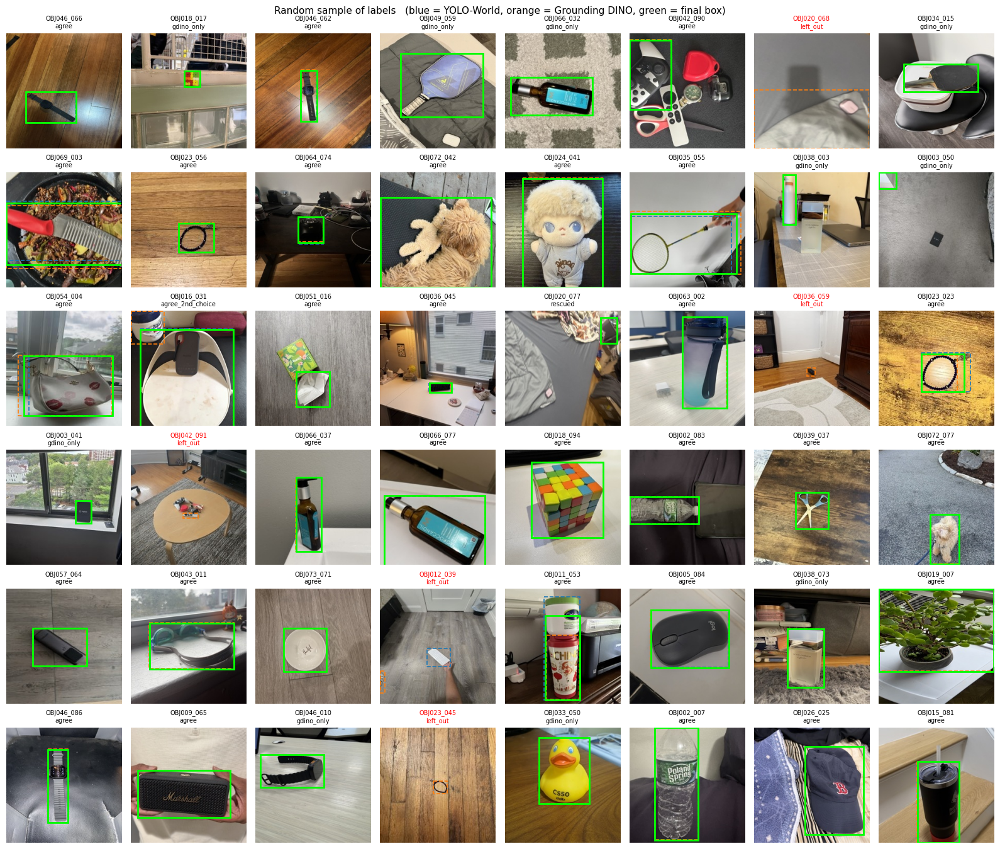

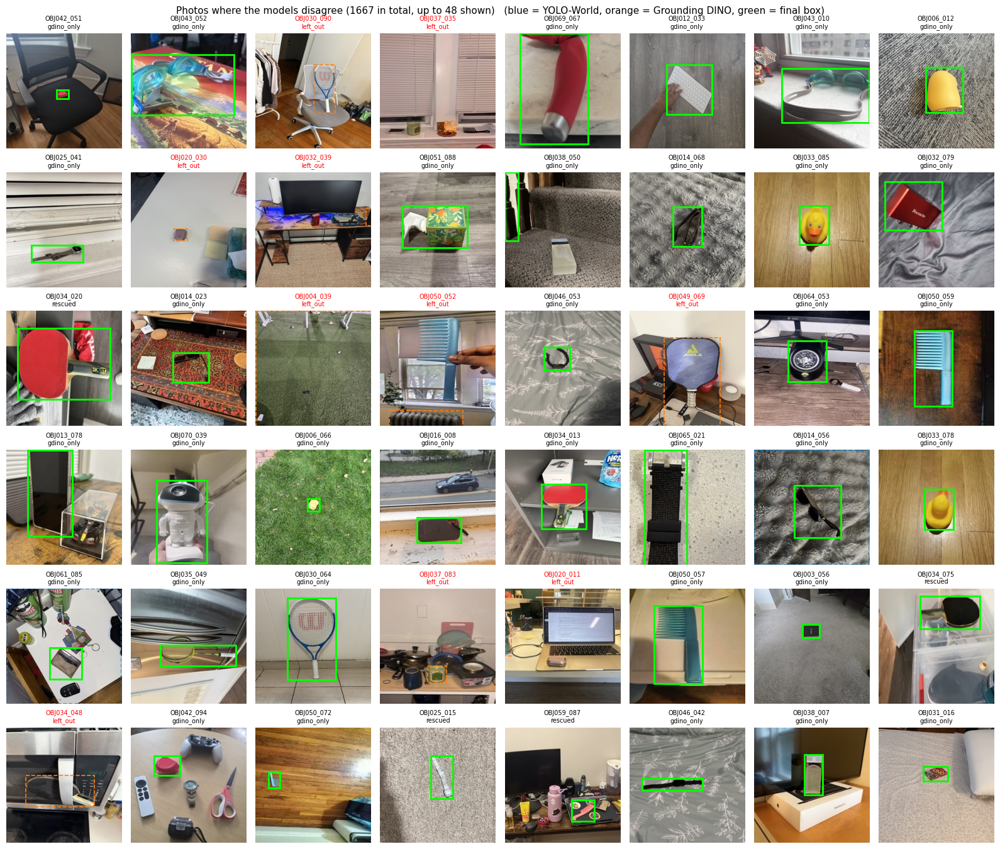

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches


def show_label_check(stems, title, fname, cols=8, size=2.0):
    stems = list(stems)
    if not stems:
        print("nothing to show:", title)
        return
    rows = (len(stems) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size * 1.15), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, stem in zip(axes.flat, stems):
        r = boxes.loc[stem]
        ax.imshow(Image.open(r.photo))
        for cands, color in [(yw_raw.get(stem, [])[:1], "tab:blue"), (gd_raw.get(stem, [])[:1], "tab:orange")]:
            for x1, y1, x2, y2, _ in cands:
                ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=1.2, ls="--"))
        if r.used:
            ax.add_patch(patches.Rectangle((r.x1, r.y1), r.x2 - r.x1, r.y2 - r.y1, fill=False, ec="lime", lw=2))
        ax.set_title(f"{stem}\n{r.status}", fontsize=7, color="black" if r.used else "red")
    fig.suptitle(f"{title}   (blue = YOLO-World, orange = Grounding DINO, green = final box)", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/{fname}", dpi=110)
    plt.show()


show_label_check(boxes.sample(min(48, len(boxes)), random_state=SEED).stem, "Random sample of labels", "label_check_random.png")
not_agree = boxes[~boxes.status.isin(["agree", "agree_2nd_choice"])]
show_label_check(not_agree.sample(min(48, len(not_agree)), random_state=SEED).stem if len(not_agree) else [],
                 f"Photos where the models disagree ({len(not_agree)} in total, up to 48 shown)", "label_check_disagree.png")
for fid in FOCUS_IDS:   # one figure per group object
    show_label_check(boxes[boxes.obj_id == fid].stem, f"All {fid} photos", f"label_check_{fid}.png", cols=10, size=1.6)

## 2.6 Multi-object grid images

> **Note (changed):** replaces the v1 generator (2–5 photos pasted on a background). Following the
> instructors' table:
>
> | Grid | Objects per image | Image size |
> |---|---|---|
> | 2×2 | 4 | 448 × 448 |
> | 3×3 | 9 | 672 × 672 |
> | 4×4 | 16 | 896 × 896 |
> | 5×4 | 20 | 1120 × 896 |
> | 5×5 | 25 | 1120 × 1120 |
>
> * **1,200 train** / 150 val / 150 test grids (final model; Milestone 2 used 800 train), with the five sizes in equal numbers in every split.
> * **Train grids use only train photos, val only val photos, test only test photos** (checked below).
> * Photos are dealt from a shuffled deck, so each photo is used about equally often and never twice in one grid.
> * **Augmentation (train only):** each tile is randomly flipped (as in v1, now with the box flipped too) and
>   gets random brightness, contrast and colour (±25%). YOLOv8 adds its own augmentation during training.
> * Labels are written in YOLO format (`class x_center y_center width height`, normalised by the grid size).
>   A zip copy of the grid dataset is saved to our Drive.

In [ ]:
t0 = time.time()
YOLO_DIR = f"{WORK_DIR}/yolo_data"    # grid images + YOLO labels
lab = boxes[boxes.used]
BUILD_CFG = dict(grids=GRID_SIZES, n=N_GRIDS, seeds=GRID_SEEDS, classes=class_names,
                 labels=hashlib.md5(lab[["stem", "split", "x1", "y1", "x2", "y2"]].round(1).to_csv().encode()).hexdigest())


def augment_tile(im, box, rng):
    if rng.random() < 0.5:   # horizontal flip, box flipped with it
        im = ImageOps.mirror(im)
        box = [TILE - box[2], box[1], TILE - box[0], box[3]]
    for enhance in (ImageEnhance.Brightness, ImageEnhance.Contrast, ImageEnhance.Color):
        im = enhance(im).enhance(rng.uniform(0.75, 1.25))
    return im, box


def make_grid(stems, cols, rows, rng=None):
    canvas = Image.new("RGB", (cols * TILE, rows * TILE))
    objs = []
    for k, stem in enumerate(stems):
        r = lab.loc[stem]
        im, box = Image.open(r.photo).convert("RGB"), [r.x1, r.y1, r.x2, r.y2]
        if rng is not None:
            im, box = augment_tile(im, box, rng)
        ox, oy = (k % cols) * TILE, (k // cols) * TILE
        canvas.paste(im, (ox, oy))
        objs.append((class_names.index(r.obj_id), box[0] + ox, box[1] + oy, box[2] + ox, box[3] + oy))
    return canvas, objs


def make_split(name, n_images, seed):
    rng = np.random.default_rng(seed)
    img_dir, lbl_dir = f"{YOLO_DIR}/images/{name}", f"{YOLO_DIR}/labels/{name}"
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)
    pool, deck, manifest = list(lab.stem[lab.split == name]), [], []
    for k in range(n_images):
        cols, rows = GRID_SIZES[k % len(GRID_SIZES)]
        need = cols * rows
        assert len(pool) >= need, f"{name}: only {len(pool)} photos for a {cols}x{rows} grid"
        if len(deck) < need:
            deck += [pool[i] for i in rng.permutation(len(pool))]
        stems, later = [], []
        while len(stems) < need:   # never the same photo twice in one grid
            s = deck.pop(0)
            (later if s in stems else stems).append(s)
        deck = later + deck
        img, objs = make_grid(stems, cols, rows, rng if name == "train" else None)
        W, H = img.size
        fname = f"{name}_{k:05d}_{cols}x{rows}"
        img.save(f"{img_dir}/{fname}.jpg", quality=95)
        with open(f"{lbl_dir}/{fname}.txt", "w") as f:
            f.write("".join(f"{c} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}\n"
                            for c, x1, y1, x2, y2 in objs))
        manifest.append(dict(grid=fname, split=name, size=f"{cols}x{rows}", width=W, height=H, n_objects=need, stems=";".join(stems)))
    print(f"{name}: {n_images} images created")
    return manifest


def write_yaml(path, val):
    with open(path, "w") as f:
        f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: {val}\ntest: images/test\nnames:\n")
        for i, n in enumerate(class_names):
            f.write(f"  {i}: {n}\n")


cfg_file = f"{YOLO_DIR}/build_config.json"
if os.path.exists(cfg_file) and json.load(open(cfg_file)) == json.loads(json.dumps(BUILD_CFG)):
    print("grid images already built")
else:
    shutil.rmtree(YOLO_DIR, ignore_errors=True)
    manifest = []
    for name in ["train", "val", "test"]:
        manifest += make_split(name, N_GRIDS[name], GRID_SEEDS[name])
    man = pd.DataFrame(manifest)
    man.to_csv(f"{YOLO_DIR}/grids_manifest.csv", index=False)
    write_yaml(f"{YOLO_DIR}/data.yaml", "images/val")   # settings file that YOLOv8 reads
    for size in man["size"].unique():   # one test list per grid size, for the per-size results
        with open(f"{YOLO_DIR}/test_{size}.txt", "w") as f:
            f.write("".join(f"{YOLO_DIR}/images/test/{g}.jpg\n" for g in man.grid[(man.split == "test") & (man["size"] == size)]))
        write_yaml(f"{YOLO_DIR}/data_test_{size}.yaml", f"test_{size}.txt")
    json.dump(BUILD_CFG, open(cfg_file, "w"))
    shutil.make_archive(f"{OUT_DIR}/grid_dataset", "zip", YOLO_DIR)   # keep a copy in our own Drive
man = pd.read_csv(f"{YOLO_DIR}/grids_manifest.csv")

used = {s: set(";".join(man.stems[man.split == s]).split(";")) for s in ["train", "val", "test"]}
assert not (used["train"] & used["val" ] or used["train"] & used["test"] or used["val"] & used["test"])
print("check passed: train, val and test grids use different photos")
display(man.groupby(["size", "split"]).agg(images=("grid", "count"), objects=("n_objects", "sum")).unstack())
print(open(f"{YOLO_DIR}/labels/train/{man.grid[0]}.txt").read())
TIMES["grids"] = (time.time() - t0) / 60

train: 1200 images created
val: 150 images created
test: 150 images created
check passed: train, val and test grids use different photos


images           objects           
split   test train val    test train  val
size                                     
2x2       30   240  30     120   960  120
3x3       30   240  30     270  2160  270
4x4       30   240  30     480  3840  480
5x4       30   240  30     600  4800  600
5x5       30   240  30     750  6000  750

72 0.303683 0.135379 0.366518 0.266518
23 0.773940 0.274777 0.241183 0.326563
51 0.249609 0.820982 0.307478 0.099554
31 0.849554 0.645982 0.247321 0.211607



### 2.6.1 Example grid images with their labels

> **Note (changed):** same idea as v1's `show_with_boxes`. It now reads the image size from the file,
> because grids have five different sizes. One example per grid size.

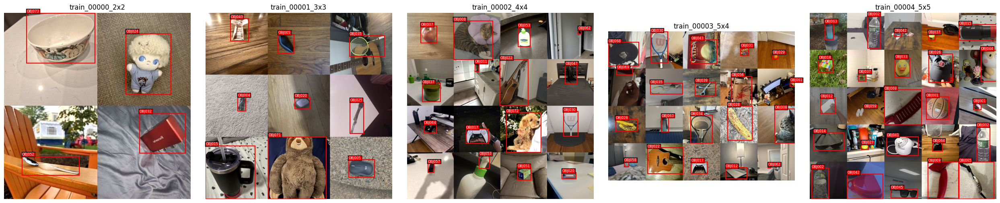

In [ ]:
def grid_path(name):
    return f"{YOLO_DIR}/images/{name.split('_')[0]}/{name}.jpg"


def read_gt(img_path):
    # YOLO label file -> list of (class, x1, y1, x2, y2) in pixels
    W, H = Image.open(img_path).size
    out = []
    for line in open(img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"):
        c, cx, cy, w, h = map(float, line.split())
        out.append((int(c), (cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H))
    return out


def show_with_boxes(name, ax):
    path = grid_path(name)
    ax.imshow(Image.open(path))
    for c, x1, y1, x2, y2 in read_gt(path):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1.5))
        ax.text(x1, y1 - 3, class_names[c], color="white", fontsize=6, bbox=dict(facecolor="red", pad=1))
    ax.axis("off")
    ax.set_title(name)


examples = [man.grid[(man.split == "train") & (man["size"] == f"{c}x{r}")].iloc[0] for c, r in GRID_SIZES]
fig, axes = plt.subplots(1, len(examples), figsize=(5 * len(examples), 5.4))
for ax, name in zip(np.atleast_1d(axes), examples):
    show_with_boxes(name, ax)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/grid_examples.png", dpi=110)
plt.show()

## 2.7 Train the final YOLOv8s model (transfer learning)

> **Note:** same model family as Milestone 2. **YOLOv8s pretrained on COCO** (11 M parameters) is fine-tuned on
> our grids, and its detection head is replaced for our 73 Object IDs. Final settings:
> * `imgsz=1120` (instructor tip). At 640, a 5×5 grid would be shrunk and each object would be only ~128 px wide.
> * `batch=8` (instructor tip for Colab; lower it if the GPU runs out of memory).
> * Up to 60 epochs, early stopping after 15 epochs without improvement. Our run used all 60 epochs (56.6 min on a T4).
> * Grid images are cached in RAM to speed up training.
> * Checkpoints are written to Drive after every epoch. If Colab disconnects, *Run all* again and training **resumes**
>   from `last.pt`.
> * The best epoch is chosen on the **validation** grids. The test grids are only used for the final results.

In [ ]:
from ultralytics import YOLO

t0 = time.time()
RUN_DIR = f"{OUT_DIR}/runs/{RUN_NAME}"
LAST, BEST, DONE = f"{RUN_DIR}/weights/last.pt", f"{RUN_DIR}/weights/best.pt", f"{RUN_DIR}/done.json"

if os.path.exists(DONE):
    print("training already finished:", json.load(open(DONE)))
else:
    if os.path.exists(LAST):
        print("resuming from", LAST)
        try:
            YOLO(LAST).train(resume=True)
        except AssertionError as e:   # last.pt belongs to a finished run
            print(e)
    else:
        model = YOLO(DET_WEIGHTS)   # small YOLOv8 model, pretrained on COCO
        results = model.train(
            data=f"{YOLO_DIR}/data.yaml",
            epochs=EPOCHS,
            imgsz=IMGSZ,
            batch=BATCH,
            patience=PATIENCE,    # stop early if validation results stop improving for 15 epochs
            seed=SEED,
            cache="ram" if GPU else False,
            device=DEVICE,
            project=f"{OUT_DIR}/runs",
            name=RUN_NAME,
            exist_ok=True,
        )
    res = pd.read_csv(f"{RUN_DIR}/results.csv")
    res.columns = res.columns.str.strip()
    json.dump(dict(epochs_run=len(res), train_min=round(float(res["time"].iloc[-1]) / 60, 1) if "time" in res else None,
                   best_val_mAP50=round(float(res["metrics/mAP50(B)"].max()), 4)), open(DONE, "w"))
    print(json.load(open(DONE)))
TIMES["train"] = (time.time() - t0) / 60

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1120, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final_yolov8s, nbs=64, nms=None, opset=None, optimize=False, op

## 2.8 Training curves and validation confusion matrix

> **Note (new):** Ultralytics already saves these figures in the run folder. The v1 report said they did not
> exist, but they did. Here they are shown and copied to `milestone2_final/figures/` for the report.

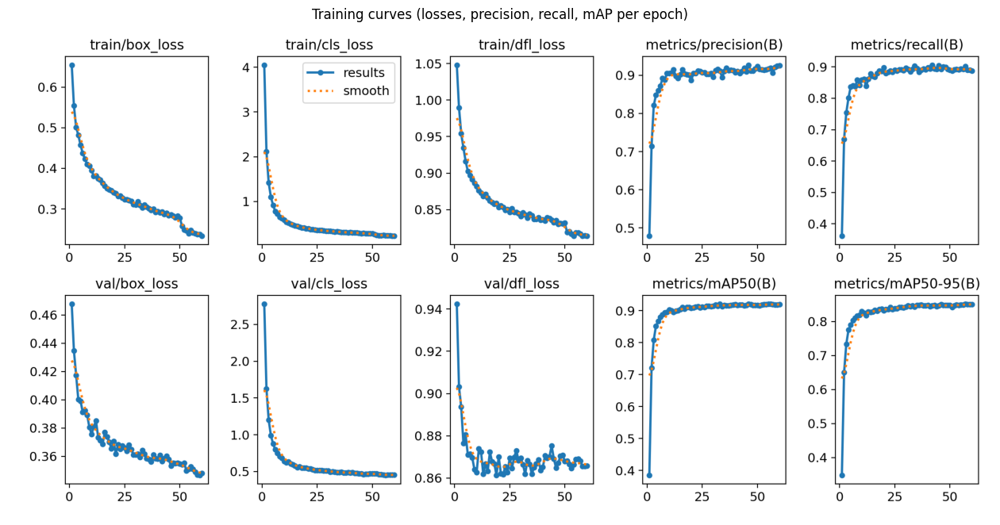

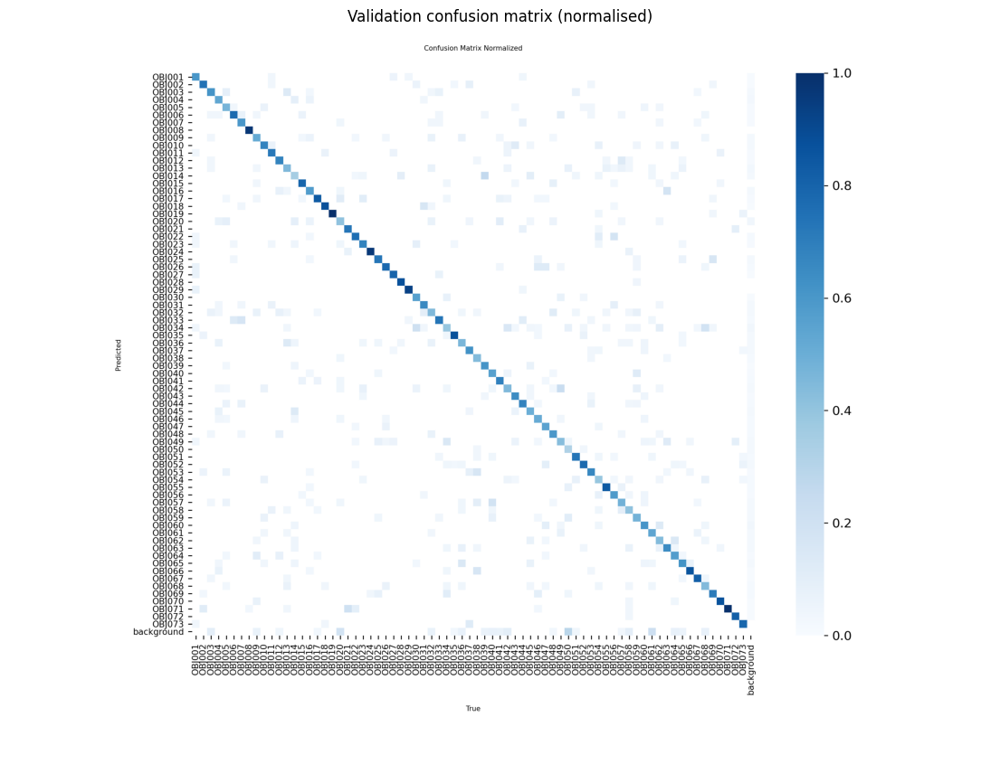

In [ ]:
for fname, title in [("results.png", "Training curves (losses, precision, recall, mAP per epoch)"),
                     ("confusion_matrix_normalized.png", "Validation confusion matrix (normalised)")]:
    path = f"{RUN_DIR}/{fname}"
    if os.path.exists(path):
        shutil.copy(path, f"{OUT_DIR}/figures/train_{fname}")
        plt.figure(figsize=(16, 9) if fname == "results.png" else (14, 12))
        plt.imshow(plt.imread(path)); plt.axis("off"); plt.title(title)
        plt.show()
    else:
        print("not found:", path)

---
# Part 3 — Milestone 3: Final model (YOLOv8s): results, error analysis and live demo

The YOLOv8s model trained in 2.7 is our **final model**. Here it is evaluated once on the 150 held-out test grids
(2,220 objects), its errors are analysed, and 3.4 runs it on new images for the live demo.

| Item | Final model |
|---|---|
| Model | **YOLOv8s**, pretrained on COCO, fine-tuned on our grids (11.2 M parameters) |
| Input size | `imgsz=1120` (448 for a single 224 × 224 photo in the demo) |
| Training data | 1,200 train / 150 val / 150 test grid images (2×2 to 5×5), built from 6,598 single photos with boxes |
| Training | 60 epochs, batch 8, patience 15, T4 GPU, 56.6 min; best epoch chosen on validation (val mAP@0.5 = 0.921) |
| **Test results** | **Precision 0.919 · Recall 0.883 · mAP@0.5 0.912 · mAP@0.5:0.95 0.856** |
| Test at confidence 0.5 | 1,958 of 2,220 objects correct (ID right and IoU ≥ 0.5); 25 of 150 grids fully correct |
| Weakest Object IDs (AP@0.5) | OBJ040, OBJ010, OBJ065, OBJ068, OBJ051 (0.63–0.70) |

> After the `FOCUS_IDS` fix, re-run Parts 2–3 once (~10–15 min with the saved labels and model) to refresh the OBJ038
> label-check figure and the OBJ036 + OBJ038 rows in 3.1 and 3.3. The other numbers will not change.

## 3.1 Test results of the final model

> **Note:** the final model is evaluated once on the 150 test grids (2,220 objects), plus:
> * the same metrics **per grid size** (2×2 … 5×5),
> * the metrics **per Object ID**, with our group's objects (`FOCUS_IDS`: OBJ036 and OBJ038) and the 10 weakest Object IDs,
> * the test confusion matrix.
>
> Precision and recall from Ultralytics are measured at the confidence threshold with the best F1 score.
> Because the boxes surround the object instead of the whole photo, **mAP@0.5:0.95 is lower than mAP@0.5**
> (0.856 vs 0.912). In v1 the two values were identical.

In [ ]:
t0 = time.time()
best_model = YOLO(BEST)
VAL_KW = dict(imgsz=IMGSZ, batch=BATCH, device=DEVICE, project=f"{OUT_DIR}/runs", exist_ok=True)

test_metrics = best_model.val(data=f"{YOLO_DIR}/data.yaml", split="test", name="test_eval", **VAL_KW)

print("\nTEST RESULTS")
print("Precision:", round(test_metrics.box.mp, 3))
print("Recall:", round(test_metrics.box.mr, 3))
print("mAP50:", round(test_metrics.box.map50, 3))
print("mAP50-95:", round(test_metrics.box.map, 3))

def box_metrics(m):
    return dict(precision=round(float(m.box.mp), 3), recall=round(float(m.box.mr), 3),
                mAP50=round(float(m.box.map50), 3), mAP50_95=round(float(m.box.map), 3))

rows = [dict(grid="all test grids", images=int((man.split == "test").sum()),
             objects=int(man.n_objects[man.split == "test"].sum()), **box_metrics(test_metrics))]
for c, r in GRID_SIZES:
    m = best_model.val(data=f"{YOLO_DIR}/data_test_{c}x{r}.yaml", split="val", name=f"test_{c}x{r}", plots=False, verbose=False, **VAL_KW)
    sel = (man.split == "test") & (man["size"] == f"{c}x{r}")
    rows.append(dict(grid=f"{c}x{r} ({c * TILE}x{r * TILE})", images=int(sel.sum()), objects=int(man.n_objects[sel].sum()), **box_metrics(m)))
test_by_grid = pd.DataFrame(rows)
test_by_grid.to_csv(f"{OUT_DIR}/test_metrics_by_grid_size.csv", index=False)
print("\nTest results per grid size:")
display(test_by_grid)

per_class = pd.DataFrame([dict(obj_id=class_names[c], **dict(zip(["precision", "recall", "AP50", "AP50_95"],
                                                                map(float, test_metrics.box.class_result(i)))))
                          for i, c in enumerate(test_metrics.box.ap_class_index)]).round(3)
per_class.to_csv(f"{OUT_DIR}/test_metrics_per_object.csv", index=False)
print("Our group's objects:", ", ".join(FOCUS_IDS))
display(per_class[per_class.obj_id.isin(FOCUS_IDS)])
print("10 weakest Object IDs (AP50):")
display(per_class.sort_values("AP50").head(10))

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2887.3±285.3 MB/s, size: 242.4 KB)
val: Scanning /content/yolo_data/labels/test... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 2.0Kit/s 0.1s
val: New cache created: /content/yolo_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.2it/s 8.8s
                   all        150       2220      0.919      0.883      0.912      0.856
                OBJ001         30         30      0.991          1      0.995      0.995
                OBJ002         28         34      0.987          1      0.995      0.995
                OBJ003         29         30        0.9      0.733      0.797      0.756
                OBJ004         28         34      0.916      0.971      0.982  

,grid,images,objects,precision,recall,mAP50,mAP50_95
0,all test grids,150,2220,0.919,0.883,0.912,0.856
1,2x2 (448x448),30,120,0.885,0.861,0.954,0.902
2,3x3 (672x672),30,270,0.895,0.872,0.927,0.881
3,4x4 (896x896),30,480,0.919,0.882,0.923,0.875
4,5x4 (1120x896),30,600,0.919,0.862,0.908,0.855
5,5x5 (1120x1120),30,750,0.912,0.890,0.911,0.855


OBJ036 (our object):


,obj_id,precision,recall,AP50,AP50_95
35,OBJ036,0.88,0.9,0.887,0.887


10 weakest Object IDs (AP50):


,obj_id,precision,recall,AP50,AP50_95
39,OBJ040,0.642,0.573,0.630,0.621
9,OBJ010,0.606,0.600,0.656,0.526
64,OBJ065,0.696,0.618,0.663,0.554
67,OBJ068,0.793,0.615,0.672,0.571
50,OBJ051,0.691,0.639,0.704,0.543
13,OBJ014,0.760,0.691,0.712,0.614
33,OBJ034,0.913,0.458,0.727,0.650
41,OBJ042,0.884,0.613,0.746,0.739
12,OBJ013,0.929,0.645,0.762,0.740
11,OBJ012,0.773,0.704,0.773,0.725


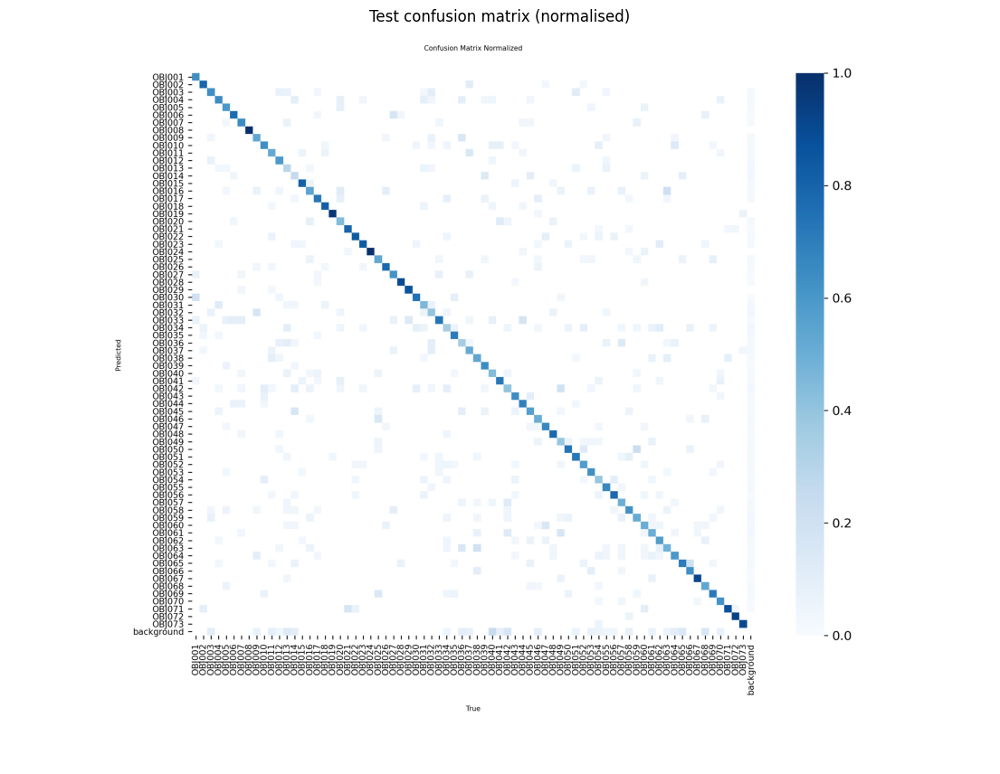

In [ ]:
path = f"{OUT_DIR}/runs/test_eval/confusion_matrix_normalized.png"
if os.path.exists(path):
    shutil.copy(path, f"{OUT_DIR}/figures/test_confusion_matrix_normalized.png")
    plt.figure(figsize=(14, 12)); plt.imshow(plt.imread(path)); plt.axis("off"); plt.title("Test confusion matrix (normalised)")
    plt.show()

## 3.2 Detect, identify and locate the objects in an image

> **Note (changed):** `detect_objects` works as in v1. It prints every object's **ID, confidence and box**
> (x1, y1, x2, y2 in pixels) and now also the **grid row / column**. It also returns the table and can draw the
> prediction next to the true labels: white dashed = true box, green = correct detection, red = wrong ID or badly
> placed box. The thick box is `FOCUS_ID` (OBJ036, the first of our group's objects).
>
> `true_labels` prints the true objects of a grid, as in v1.

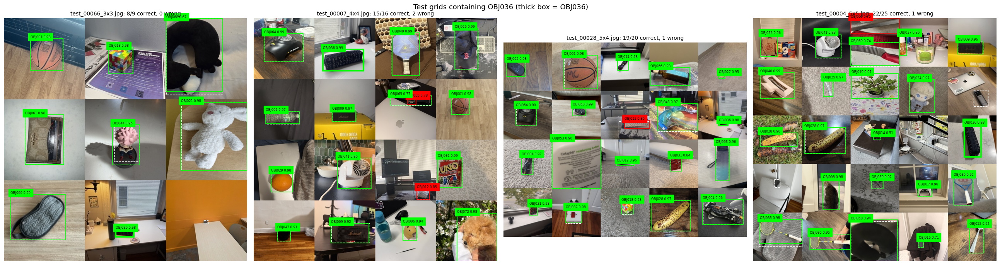

Image: test_00004_5x5.jpg | objects found: 23


,object_id,confidence,x1,y1,x2,y2,row,col
0,OBJ056,0.96,34,75,112,175,1,1
1,OBJ041,0.98,287,72,404,183,1,2
2,OBJ069,0.75,448,0,672,69,1,3
3,OBJ069,0.74,449,111,672,218,1,3
4,OBJ037,0.96,672,73,707,172,1,4
5,OBJ009,0.96,941,104,1057,165,1,5
6,OBJ040,0.99,32,251,189,369,2,1
7,OBJ025,0.97,322,279,366,361,2,2
8,OBJ019,0.97,451,254,668,369,2,3
9,OBJ024,0.97,719,282,835,434,2,4


TRUE objects in test_00004_5x5:


,object_id,x1,y1,x2,y2,row,col
0,OBJ056,34,76,112,174,1,1
1,OBJ041,288,72,405,183,1,2
2,OBJ069,448,110,672,223,1,3
3,OBJ037,672,74,706,170,1,4
4,OBJ009,941,105,1057,164,1,5
5,OBJ040,32,251,189,370,2,1
6,OBJ025,322,279,365,361,2,2
7,OBJ019,450,254,663,367,2,3
8,OBJ024,718,282,835,434,2,4
9,OBJ057,1014,330,1081,406,2,5


OBJ036 found at: [[3.0, 5.0, 972.0, 488.0, 1048.0, 639.0, 0.98]]


In [ ]:
def detect_objects(image_path, conf=CONF, ax=None, verbose=True):
    result = best_model.predict(image_path, imgsz=IMGSZ, conf=conf, device=DEVICE, verbose=False)[0]
    rows = []
    for box in result.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        rows.append(dict(object_id=class_names[int(box.cls[0])], confidence=round(float(box.conf[0]), 2),
                         x1=round(x1), y1=round(y1), x2=round(x2), y2=round(y2),
                         row=int((y1 + y2) / 2 // TILE) + 1, col=int((x1 + x2) / 2 // TILE) + 1))
    det = pd.DataFrame(rows, columns=["object_id", "confidence", "x1", "y1", "x2", "y2", "row", "col"])
    det = det.sort_values(["row", "col"]).reset_index(drop=True)
    if verbose:
        print(f"Image: {os.path.basename(image_path)} | objects found: {len(det)}")
        display(det)
    if ax is not None:
        gt = read_gt(image_path) if "/images/" in image_path else None
        ax.imshow(Image.open(image_path)); ax.axis("off")
        for c, x1, y1, x2, y2 in gt or []:
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="white", lw=1, ls="--"))
        n_ok = 0
        for d in det.itertuples():
            ok = gt is None or any(class_names[c] == d.object_id and iou([d.x1, d.y1, d.x2, d.y2], b) >= 0.5 for c, *b in gt)
            n_ok += ok
            color = "lime" if ok else "red"
            ax.add_patch(patches.Rectangle((d.x1, d.y1), d.x2 - d.x1, d.y2 - d.y1, fill=False, ec=color,
                                           lw=3 if d.object_id == FOCUS_ID else 1.2))
            ax.text(d.x1, d.y1, f"{d.object_id} {d.confidence:.2f}", fontsize=6, color="black", backgroundcolor=color, va="bottom")
        if gt is not None:
            ax.set_title(f"{os.path.basename(image_path)}: {n_ok}/{len(gt)} correct, {len(det) - n_ok} wrong", fontsize=10)
    return det


def true_labels(name):
    print(f"TRUE objects in {name}:")
    gt = pd.DataFrame([dict(object_id=class_names[c], x1=round(x1), y1=round(y1), x2=round(x2), y2=round(y2),
                            row=int((y1 + y2) / 2 // TILE) + 1, col=int((x1 + x2) / 2 // TILE) + 1)
                       for c, x1, y1, x2, y2 in read_gt(grid_path(name))])
    display(gt.sort_values(["row", "col"]).reset_index(drop=True))


# example: test grids that contain OBJ036, one per grid size
focus_stems = set(lab.stem[lab.obj_id == FOCUS_ID])
test_grids = man[man.split == "test"]
has_focus = test_grids[test_grids.stems.apply(lambda s: bool(focus_stems & set(s.split(";"))))]
picks = [has_focus.grid[has_focus["size"] == f"{c}x{r}"].iloc[0] for c, r in GRID_SIZES if (has_focus["size"] == f"{c}x{r}").any()]
picks = picks[-4:] if picks else list(test_grids.grid[:4])
fig, axes = plt.subplots(1, len(picks), figsize=(6.5 * len(picks), 7))
for ax, name in zip(np.atleast_1d(axes), picks):
    detect_objects(grid_path(name), ax=ax, verbose=False)
plt.suptitle(f"Test grids containing {FOCUS_ID} (thick box = {FOCUS_ID})", fontsize=13)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/example_detections.png", dpi=120)
plt.show()

det = detect_objects(grid_path(picks[-1]))
true_labels(picks[-1])
print(f"{FOCUS_ID} found at:", det.loc[det.object_id == FOCUS_ID, ["row", "col", "x1", "y1", "x2", "y2", "confidence"]].values.tolist())

### 3.2.1 All test grids at confidence 0.5, and error analysis

> **Note (new):** v1 showed one example. This cell runs `detect_objects` on **every test grid** at the
> same threshold (0.5). A detection is correct when the Object ID is right and the box overlaps the true box with
> IoU ≥ 0.5. It reports:
> * correct / wrong / missed objects and the number of grids where **every** object was found with nothing extra,
>   per grid size,
> * which Object IDs are missed most, and which IDs are confused with which,
> * a figure with examples of missed objects, as input for the report's error analysis.

Test grids at confidence 0.5:


,images,objects,correct,wrong_or_extra,missed,grids_all_correct,precision,recall
size,,,,,,,,
2x2,30,120,102,6,18,16,0.944,0.850
3x3,30,270,237,23,33,6,0.912,0.878
4x4,30,480,425,38,55,2,0.918,0.885
5x4,30,600,525,37,75,1,0.934,0.875
5x5,30,750,669,52,81,0,0.928,0.892
all,150,2220,1958,156,262,25,0.926,0.882


Object IDs with the most missed or wrongly identified test objects:


,errors
true_id,
OBJ051,15
OBJ065,13
OBJ013,12
OBJ034,12
OBJ061,11
OBJ068,11
OBJ010,10
OBJ040,10
OBJ003,10


Most frequent confusions (true -> predicted):


,,count
true_id,predicted_id,
OBJ003,OBJ012,2
OBJ060,OBJ014,2
OBJ014,OBJ004,1
OBJ020,OBJ005,1
OBJ034,OBJ045,1
OBJ057,OBJ055,1


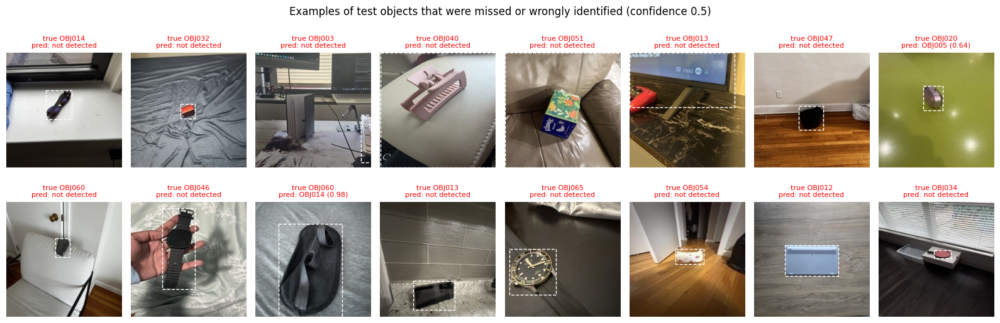

In [ ]:
def match(pred, gt, conf):
    # greedy by confidence: correct if same Object ID and IoU >= 0.5 with a true box that is not matched yet
    cls, cf, xy = pred
    keep = [i for i in np.argsort(cf)[::-1] if cf[i] >= conf]
    taken, ok = set(), []
    for i in keep:
        best, bj = 0.5, None
        for j, (c, *b) in enumerate(gt):
            if j not in taken and c == cls[i] and iou(xy[i], b) >= best:
                best, bj = iou(xy[i], b), j
        if bj is not None:
            taken.add(bj)
        ok.append(bj is not None)
    return keep, ok, taken


test_paths = [grid_path(g) for g in test_grids.grid]
preds = {}
for i in range(0, len(test_paths), 8):   # 8 grids at a time (1120 px) to stay within GPU memory
    batch = test_paths[i:i + 8]
    for p, r in zip(batch, best_model.predict(batch, imgsz=IMGSZ, conf=CONF, device=DEVICE, verbose=False)):
        preds[p] = (r.boxes.cls.int().tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())

per_img, errors = [], []
for p, pred in preds.items():
    gt = read_gt(p)
    keep, ok, taken = match(pred, gt, CONF)
    per_img.append(dict(size=os.path.basename(p)[:-4].split("_")[-1], objects=len(gt), correct=sum(ok),
                        wrong_or_extra=len(ok) - sum(ok), missed=len(gt) - len(taken)))
    cls, cf, xy = pred
    for j, (c, *b) in enumerate(gt):
        if j not in taken:
            o, i = max(((iou(xy[i], b), i) for i in keep), default=(0, None))
            errors.append(dict(path=p, box=b, true_id=class_names[c],
                               predicted=f"{class_names[cls[i]]} ({cf[i]:.2f})" if o >= 0.5 else "not detected",
                               predicted_id=class_names[cls[i]] if o >= 0.5 else None))
per_img = pd.DataFrame(per_img)
per_img["all_correct"] = (per_img.wrong_or_extra == 0) & (per_img.missed == 0)
by_size = per_img.groupby("size").agg(images=("objects", "size"), objects=("objects", "sum"), correct=("correct", "sum"),
                                      wrong_or_extra=("wrong_or_extra", "sum"), missed=("missed", "sum"),
                                      grids_all_correct=("all_correct", "sum"))
by_size.loc["all"] = by_size.sum()
by_size["precision"] = (by_size.correct / (by_size.correct + by_size.wrong_or_extra).clip(lower=1)).round(3)
by_size["recall"] = (by_size.correct / by_size.objects).round(3)
by_size.to_csv(f"{OUT_DIR}/test_detection_at_conf{CONF}.csv")
print(f"Test grids at confidence {CONF}:")
display(by_size)

errors = pd.DataFrame(errors, columns=["path", "box", "true_id", "predicted", "predicted_id"])
print("Object IDs with the most missed or wrongly identified test objects:")
display(errors.true_id.value_counts().head(10).rename("errors"))
print("Most frequent confusions (true -> predicted):")
display(errors.dropna(subset=["predicted_id"]).groupby(["true_id", "predicted_id"]).size().sort_values(ascending=False).head(10).rename("count"))

n = min(16, len(errors))
if n:
    show = errors.sample(n, random_state=SEED)
    fig, axes = plt.subplots((n + 7) // 8, 8, figsize=(16, 2.8 * ((n + 7) // 8)), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, e in zip(axes.flat, show.itertuples()):
        x1, y1, x2, y2 = e.box
        col, row = int((x1 + x2) / 2 // TILE), int((y1 + y2) / 2 // TILE)
        ax.imshow(Image.open(e.path).crop((col * TILE, row * TILE, (col + 1) * TILE, (row + 1) * TILE)))
        ax.add_patch(patches.Rectangle((x1 - col * TILE, y1 - row * TILE), x2 - x1, y2 - y1, fill=False, ec="white", ls="--"))
        ax.set_title(f"true {e.true_id}\npred: {e.predicted}", fontsize=8, color="red")
    plt.suptitle(f"Examples of test objects that were missed or wrongly identified (confidence {CONF})")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/test_errors.png", dpi=110)
    plt.show()
TIMES["evaluate"] = (time.time() - t0) / 60

## 3.3 Final model summary for the report

> **Note:** collects every number the instructors asked for: Object IDs, grid sizes, how the labels were made
> and checked, photos left out per Object ID, metrics, training details and timings. It is saved as
> `milestone2_final/week2_summary.json`. The final model is copied to `milestone2_final/best_final_yolov8s.pt`.

In [ ]:
shutil.copy(BEST, f"{OUT_DIR}/best_{RUN_NAME}.pt")
TIMES["total_this_session"] = (time.time() - T_START) / 60
summary = dict(
    object_ids=f"{len(class_names)} IDs ({class_names[0]}–{class_names[-1]})",
    grid_sizes=[f"{c}x{r} ({c * TILE}x{r * TILE})" for c, r in GRID_SIZES],
    photos=dict(unique=len(photos),
                removed_before_split={k: int(v) for k, v in removed.reason.str.replace(r" of OBJ.*|:.*", "", regex=True).value_counts().items()},
                **{k: int(v) for k, v in photos.split.value_counts().items()}),
    labels=LABEL_STATS,
    left_out_per_object={k: int(v) for k, v in per_obj.left_out[per_obj.left_out > 0].items()},
    grids={s: int((man.split == s).sum()) for s in ["train", "val", "test"]},
    objects_in_grids={s: int(man.n_objects[man.split == s].sum()) for s in ["train", "val", "test"]},
    training=dict(model=DET_WEIGHTS, imgsz=IMGSZ, batch=BATCH, max_epochs=EPOCHS, patience=PATIENCE, **json.load(open(DONE))),
    test=test_by_grid.iloc[0][["precision", "recall", "mAP50", "mAP50_95"]].to_dict(),
    test_by_grid=test_by_grid.set_index("grid")[["precision", "recall", "mAP50", "mAP50_95"]].to_dict("index"),
    test_at_conf=dict(conf=CONF, **{k: (int(v) if k not in ("precision", "recall") else float(v)) for k, v in by_size.loc["all"].items()}),
    focus_objects=per_class[per_class.obj_id.isin(FOCUS_IDS)].to_dict("records"),
    minutes={k: round(v, 1) for k, v in TIMES.items()},
)
json.dump(summary, open(f"{OUT_DIR}/week2_summary.json", "w"), indent=1, default=str)
print(json.dumps(summary, indent=1, default=str))

{
 "object_ids": "73 IDs (OBJ001\u2013OBJ073)",
 "grid_sizes": [
  "2x2 (448x448)",
  "3x3 (672x672)",
  "4x4 (896x896)",
  "5x4 (1120x896)",
  "5x5 (1120x1120)"
 ],
 "photos": {
  "unique": 6947,
  "removed_before_split": {
   "exact duplicate": 16,
   "excluded": 1
  },
  "train": 4862,
  "test": 1043,
  "val": 1042
 },
 "labels": {
  "photos": 6947,
  "used": 6598,
  "left_out": 349,
  "models_agree": 5280,
  "agree_pct": 76.0,
  "mean_iou_when_agree": 0.944,
  "status_counts": {
   "agree": 4712,
   "gdino_only": 1180,
   "agree_2nd_choice": 568,
   "left_out": 349,
   "rescued": 130,
   "yoloworld_only": 8
  }
 },
 "left_out_per_object": {
  "OBJ003": 8,
  "OBJ004": 6,
  "OBJ007": 1,
  "OBJ009": 1,
  "OBJ012": 8,
  "OBJ013": 9,
  "OBJ014": 11,
  "OBJ017": 1,
  "OBJ020": 19,
  "OBJ023": 7,
  "OBJ025": 18,
  "OBJ026": 1,
  "OBJ029": 1,
  "OBJ030": 6,
  "OBJ031": 2,
  "OBJ032": 11,
  "OBJ033": 8,
  "OBJ034": 19,
  "OBJ036": 19,
  "OBJ037": 19,
  "OBJ038": 2,
  "OBJ040": 15,
  "OBJ041

## 3.4 Live demo: run the final model on new images

> **Note (new):** a stand-alone cell for the live demo. It mounts Drive, loads the final weights
> (`milestone2_final/runs/final_yolov8s/weights/best.pt`) and asks you to upload images (select all at once).
> * **(a) Single object:** a photo of 336 px or smaller is treated as one 224 px photo and run at `imgsz=448`.
> * **(b) Multi-object grid:** anything larger is run at `imgsz=1120`.
>
> For each image it shows the detections and a table with every object's **ID, confidence, box (x1, y1, x2, y2)
> and grid row / column**, at confidence 0.5. The table is also saved as `<image name>_detections.csv`.
> This covers both demo tasks. The cell can run on its own after a restart, so the full notebook does not need to be re-run for the demo.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Saving test_00002_4x4.jpg to test_00002_4x4.jpg
Saving test_00010_2x2.jpg to test_00010_2x2.jpg
Saving test_00015_2x2.jpg to test_00015_2x2.jpg
Saving test_00020_2x2.jpg to test_00020_2x2.jpg
Saving test_00051_3x3.jpg to test_00051_3x3.jpg

test_00002_4x4.jpg: 15 objects found


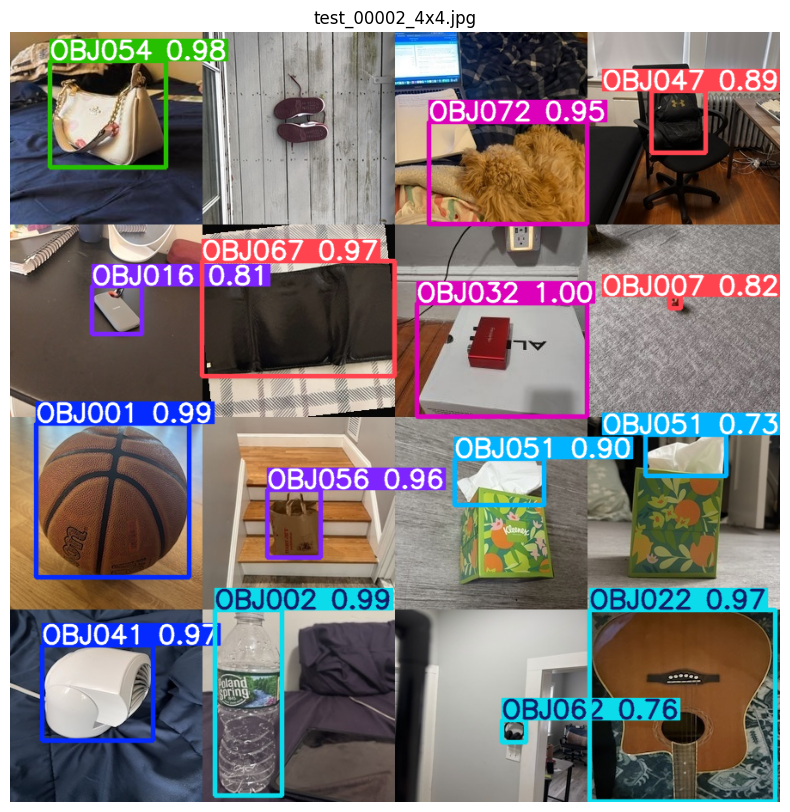

,object_id,confidence,x1,y1,x2,y2,row,col
0,OBJ054,0.98,47,34,182,157,1,1
1,OBJ072,0.95,487,105,672,224,1,3
2,OBJ047,0.89,746,69,809,141,1,4
3,OBJ016,0.81,96,295,153,352,2,1
4,OBJ067,0.97,224,266,448,401,2,2
5,OBJ032,1.00,473,315,672,448,2,3
6,OBJ007,0.82,767,307,780,322,2,4
7,OBJ001,0.99,30,455,209,635,3,1
8,OBJ056,0.96,300,533,361,611,3,2
9,OBJ051,0.90,518,496,621,550,3,3



test_00010_2x2.jpg: 4 objects found


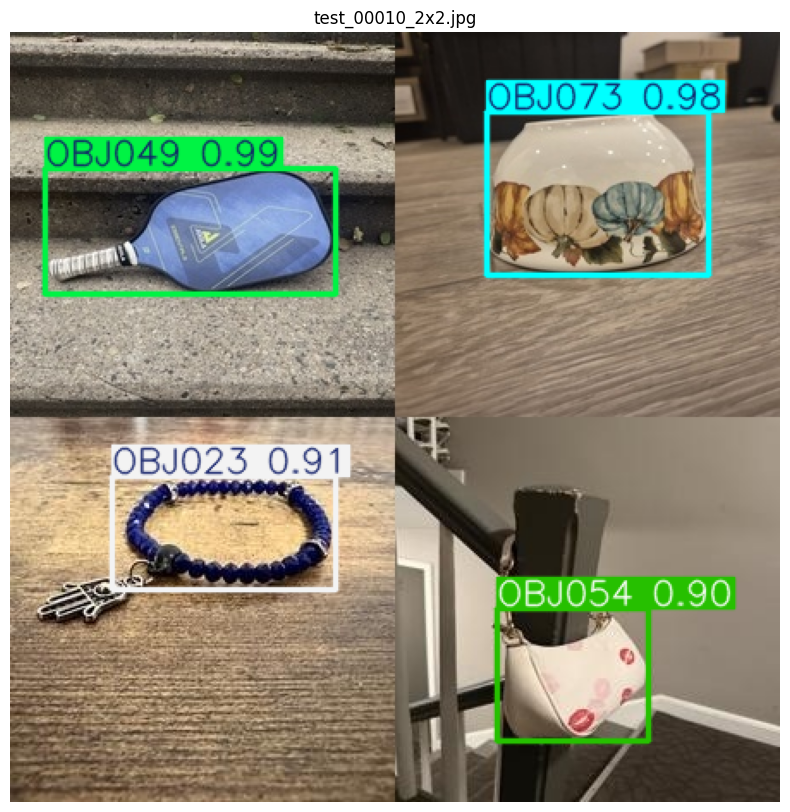

,object_id,confidence,x1,y1,x2,y2,row,col
0,OBJ049,0.99,20,79,190,153,1,1
1,OBJ073,0.98,277,46,406,141,1,2
2,OBJ023,0.91,60,258,190,325,2,1
3,OBJ054,0.90,284,335,371,412,2,2



test_00015_2x2.jpg: 4 objects found


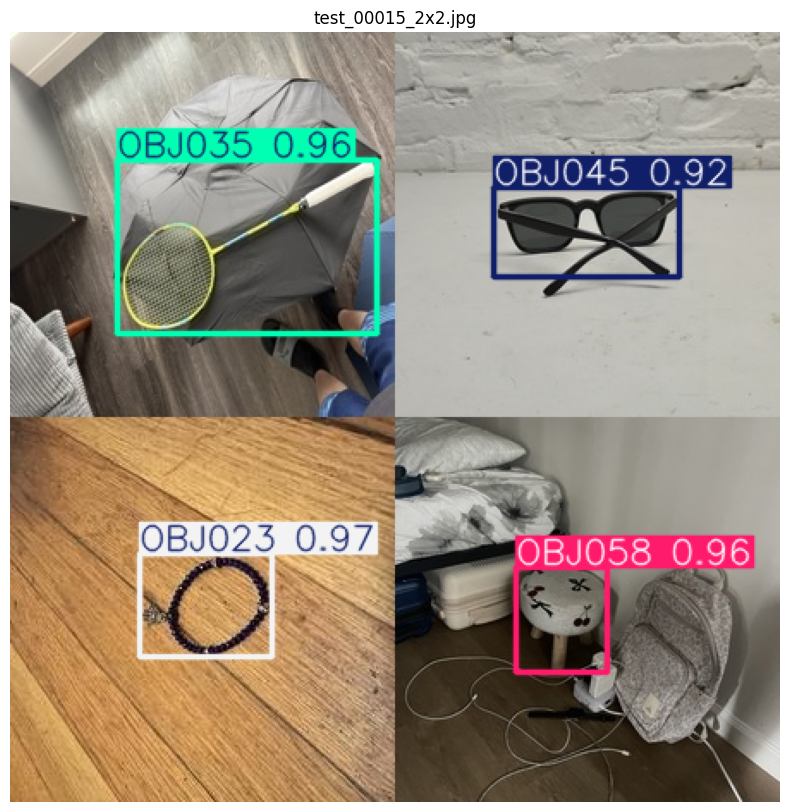

,object_id,confidence,x1,y1,x2,y2,row,col
0,OBJ035,0.96,63,75,214,175,1,1
1,OBJ045,0.92,282,91,389,142,1,2
2,OBJ023,0.97,76,304,153,364,2,1
3,OBJ058,0.96,295,311,348,373,2,2



test_00020_2x2.jpg: 2 objects found


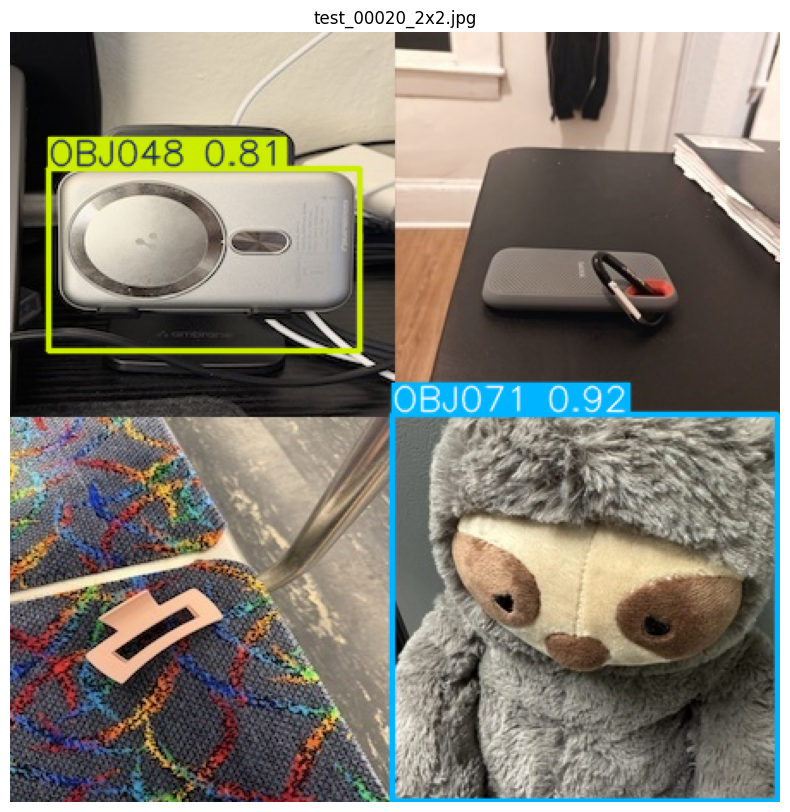

,object_id,confidence,x1,y1,x2,y2,row,col
0,OBJ048,0.81,23,79,203,186,1,1
1,OBJ071,0.92,222,222,446,448,2,2



test_00051_3x3.jpg: 9 objects found


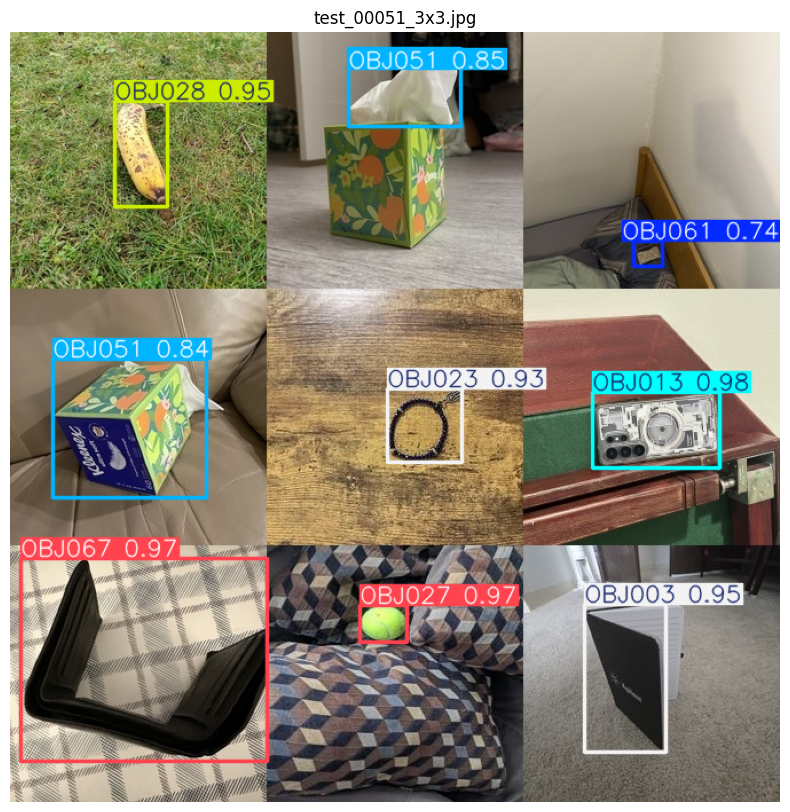

,object_id,confidence,x1,y1,x2,y2,row,col
0,OBJ028,0.95,91,61,138,153,1,1
1,OBJ051,0.85,295,14,394,82,1,2
2,OBJ061,0.74,544,182,569,204,1,3
3,OBJ051,0.84,38,285,171,407,2,1
4,OBJ023,0.93,330,312,394,375,2,2
5,OBJ013,0.98,509,315,619,380,2,3
6,OBJ067,0.97,9,459,224,636,3,1
7,OBJ027,0.97,306,500,347,532,3,2
8,OBJ003,0.95,502,500,573,629,3,3


In [ ]:
# ===== Milestone 3: run the trained model on new images =====
import os, sys
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from google.colab import drive, files
drive.mount("/content/drive")
!pip -q install ultralytics
from ultralytics import YOLO

MODEL = "/content/drive/MyDrive/milestone2_final/runs/final_yolov8s/weights/best.pt"
model = YOLO(MODEL)
CONF, TILE = 0.5, 224

for name, data in files.upload().items():          # pick all 5 images at once
    open(name, "wb").write(data)
    img = ImageOps.exif_transpose(Image.open(name)).convert("RGB")
    small = max(img.size) <= 336                       # a single 224 px photo
    r = model.predict(img, imgsz=448 if small else 1120, conf=CONF, verbose=False)[0]
    rows = [dict(object_id=model.names[int(c)], confidence=round(float(s), 2),
                 x1=round(b[0]), y1=round(b[1]), x2=round(b[2]), y2=round(b[3]),
                 row=int((b[1] + b[3]) / 2 // TILE) + 1, col=int((b[0] + b[2]) / 2 // TILE) + 1)
            for c, s, b in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())]
    det = pd.DataFrame(rows, columns=["object_id", "confidence", "x1", "y1", "x2", "y2", "row", "col"])
    det = det.sort_values(["row", "col"]).reset_index(drop=True)
    print(f"\n{name}: {len(det)} objects found")
    plt.figure(figsize=(10, 10)); plt.imshow(r.plot()[..., ::-1]); plt.axis("off"); plt.title(name); plt.show()
    display(det)
    det.to_csv(name.rsplit(".", 1)[0] + "_detections.csv", index=False)